# ESACT 2026: Hybrid modelling workshop 

All materials available at: https://github.com/leogundersen/CHOHybDeep

First, run "git clone https://github.com/leogundersen/CHOHybDeep.git"

In [1]:
#run once and delete after
#%pip install -r requirements.txt

In [2]:
##################################### Cell 0: Libraries #############################################################
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import random
import time
import os
import requests
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
import itertools
from pathlib import Path
from tqdm import tqdm
import torch._dynamo
import math
import fnmatch
import optuna 

torch._dynamo.config.recompile_limit = 100
torch._dynamo.config.cache_size_limit = 200

#"C:\Program Files\Microsoft Visual Studio\18\Community\VC\Auxiliary\Build\vcvars64.bat"

REPO = "leogundersen/CHOHybDeep"
BRANCH = "main"
RAW_BASE = f"https://raw.githubusercontent.com/{REPO}/{BRANCH}"

def get_repo_file_list():
    """One API call, returns every file path in the repo."""
    url = f"https://api.github.com/repos/{REPO}/git/trees/{BRANCH}?recursive=1"
    resp = requests.get(url, timeout=30)
    resp.raise_for_status()
    data = resp.json()
    return [item["path"] for item in data["tree"] if item["type"] == "blob"]

REPO_FILES = get_repo_file_list()


EXCEL_DIR = f"{RAW_BASE}/Excel"
DATA_DIR = f"{RAW_BASE}/Data"
RESULTS_DIR = f"{RAW_BASE}/Results"
CODE_DIR = f"{RAW_BASE}/Code"

In [3]:
################################# Cell 1: Variables and Parameters ################################################

#---------------------------------------------- Optuna ------------------------------------------------------------
run_training = True                            #run Optuna or not
N_TRIALS = 65                                   #number of trials for Optuna

#----------------------------- Model Parameters, Structure, Datasplit ---------------------------------------------
AICc = True                                     #use AICc or CV for regularization and model selection
LOOCV = False                                   #use LOOCV or k-fold for cross-validation (only used if AICc = False)

test_roles = []                                 #choose test batches based on DoE roles ("Cube", "Star", "Center")

if AICc == True:
    #AICc method
    k_folds = 1                                 #number of different partitions (k fold) - Does not change in Optuna
    num_val = 0                                 #number of validation batches - Does not change in Optuna
else:
    if LOOCV == True:
        #LOOCV method
        k_folds = 14                            #One for each training batch - Does not change in Optuna
        num_val = 1                             #One for each training batch - Does not change in Optuna
    else: 
        #kfold method
        k_folds = 5                             #number of different partitions (k fold) - Does not change in Optuna
        num_val = 4                             #number of validation batches - Does not change in Optuna

n_pc = 25                                       #number of PCs used (equal to NN outputs)
nh = [20]                                       #hidden layer structure (number of neurons per layer)
weight_dropout_rate = 0.2                       #prob of inactive neuron (stochastic regularization)
train_minibatch_rate = 0.8                      #rate of batches randomly selected for training on each epoch from overall training set
h = 3                                           #h  = integration step size
lr, weight_decay, epochs = 1e-3, 1e-4, 5000     #learning rate, weight decay, number of epochs

outputs_num = n_pc                              #number of NN outputs
inputs_num = outputs_num + 1                    #len(inputs_labels) + 1  # +1 for state (0 or 1)

activation = 'tanh' if len(nh) == 1 else 'relu' #activation function 

#------------------------------------- Feed and Input Data --------------------------------------------------------
#feed concentrations (mmol/L, except X and mAB (mg/L))
#                         X,   mAb, ALA, ARG,   ASN,  ASP,  CYS,  AGLC, EGLN, EGLU, EPYR,   GLY, HIS,   ILE,   LAC, LEU,    LYS,  MET,  NH4, PHE,    PRO,     SER,     THR,   TYR, VAL, 
Feed_Conc = torch.Tensor([0.0, 0.0, 0.0, 29.71, 15.0, 25.0, 3.32, 500,  5.0,  5.0,  9.9175, 0.0, 11.73, 11.74, 0.0, 13.855, 1.02, 3.57, 0.0, 5.9725, 10.3275, 24.3233, 32.12, 2.0, 11.242])

#labels of state variables (ODEs)
inputs_labels = ['X(gDW/L)', 'mAB(mg/L)', 'ALA(mM)', 'ARG(mM)', 'ASN(mM)',
                    'ASP(mM)', 'CYS(mM)', 'EGLC(mM)', 'EGLN(mM)',
                    'EGLU(mM)', 'EPYR(mM)', 'GLY(mM)', 'HIS(mM)',
                    'ILE(mM)', 'LAC(mM)', 'LEU(mM)', 'LYS(mM)',
                    'MET(mM)', 'NH4(mM)', 'PHE(mM)', 'PRO(mM)',
                    'SER(mM)', 'THR(mM)', 'TYR(mM)', 'VAL(mM)'] 

control_labels = ["feed_rate", "feed_state"]    #L/h and (0,1), respectively
volume_label = "V(L)"
time_label = "t(h)"
    
output_max = [3.4413529647281393e-02, 23.58652837574482, 1.794038325897418e-02, 3.8248967939580325e-03, 8.076574886217713e-03,
              8.773932677286211e-03, 2.3315399175771745e-03, 0.47235877718776464, 1.259290274902014e-02, 5.3099661272202666e-03,
              8.812797204882372e-03, 1.3182995644456241e-02, 2.5753706722753122e-03, 2.9300701953616226e-03, 1.3655280781676993e-02,
              8.601619811088312e-03, 7.5830789683095645e-03, 1.2054237004122115e-03, 2.363916610192973e-02, 3.740357897186186e-03,
              5.423622042144416e-03, 2.5312401703558862e-02, 1.568819789099507e-02, 1.1240928188271937e-03, 9.986263648897875e-03] #maximum rates across batches/times

output_max = torch.tensor(output_max) #mmol/L/h (maximum rates for denormalization of NN output)

In [4]:
############################################ Cell 3: File Extraction from Repository ###########################################

#----------------------------------------------- mAb Selection (random or manual) ----------------------------------------------
mABs_to_train = ['Adalimumab']      #name of mAbs to select manually
num_mabs_to_select = 0              #number of mAbs to select randomly (if 0, mABs_to_train is used)

dfinfo = pd.read_csv(f"{EXCEL_DIR}/mAB_info_LG_final.csv", index_col=False)      #load excel with mAb names and vmaxmabs
mabnames_list = dfinfo['Name'].iloc[:].tolist()                                 #load names of mabs    

seed_value = 2026                 #seed random selection of mABs
random.seed(seed_value)         #ensure its random
np.random.seed(seed_value)      #ensure its random
torch.manual_seed(seed_value)   #ensure its random

if num_mabs_to_select != 0:          #randomly select mAbs when num_mabs_to_select is not 0        
    mABs_to_train = random.sample(mabnames_list, num_mabs_to_select) 
else:                                #else count number of mAbs written in mABs_to_train               
    num_mabs_to_select = len(mABs_to_train)

print(f"Number of mAbs selected: {num_mabs_to_select}")                         #print mABs selected   

#-------------------------------------------- Batch selection based on DoE framework ----------------------------------------------
DoE_framework = [
    "_96_0.0_1.5_20260904",         #0  #Star
    "_96_0.4_1.5_20260904",         #1  #Star
    "_96_0.2_0.0_20260904",         #2  #Star
    "_96_0.2_3.0_20260904",         #3  #Star

    "_96_0.2_1.5_20260904",         #4  #Center

    "_84_0.081_0.61_20260904",      #5  #Cube
    "_84_0.081_2.39_20260904",      #6  #Cube
    "_84_0.319_0.61_20260904",      #7  #Cube
    "_84_0.319_2.39_20260904",      #8  #Cube

    "_108_0.081_0.61_20260904",     #9  #Cube
    "_108_0.081_2.39_20260904",     #10 #Cube
    "_108_0.319_0.61_20260904",     #11 #Cube
    "_108_0.319_2.39_20260904",     #12 #Cube

    "_72_0.2_1.5_20260904",         #13 #Star
    "_120_0.2_1.5_20260904"         #14 #Star
    ]

DoE_roles = ["Star", "Star", "Star", "Star",   # 0-3   batches are Star points
            "Center",                          #  4    batch is Center point
            "Cube", "Cube", "Cube", "Cube",    # 5-8   batches are Cube points
            "Cube", "Cube", "Cube", "Cube",    # 9-12  batches are Cube points
            "Star", "Star"]                    # 13-14 batches are Star points

assert len(DoE_roles) == len(DoE_framework)    #ensure roles and batches match in length
        
#find mAB in folders within ROOT path
def find_mab_folder(mab: str) -> str:
    for productivity in ["high", "low"]:
        prefix = f"Data/{productivity}/{mab}/"
        if any(p.startswith(prefix) for p in REPO_FILES):
            return f"Data/{productivity}/{mab}"
    raise FileNotFoundError(f"mAb '{mab}' not found in high/ or low/")

def find_doe_files(mab: str, mab_folder: str, doe_framework: list[str]):
    urls = []
    for doe in doe_framework:
        pattern = f"{mab_folder}/{mab}{doe}*.csv"
        matches = sorted(p for p in REPO_FILES if fnmatch.fnmatch(p, pattern))
        if not matches:
            raise FileNotFoundError(f"No file found for pattern: {pattern}")
        urls.append(f"{RAW_BASE}/{matches[-1]}")   # build the raw download URL
    return urls

filenames_path = []
for mab in mABs_to_train:
    mab_folder = find_mab_folder(mab)
    filenames_path.extend(find_doe_files(mab, mab_folder, DoE_framework))
filenames_batches = filenames_path   

#create tag
method = "AICc" if AICc else "kfold" if not LOOCV else "LOOCV"
full_layers = [inputs_num] + nh + [outputs_num]
model_tag = "_".join(map(str, full_layers))
mab_tag = "_".join(mABs_to_train)
arch_tag = f"{mab_tag}_{model_tag}_{method}"

print(arch_tag)

Number of mAbs selected: 1
Adalimumab_26_20_25_AICc


In [5]:
############################################ Cell 4: Load and Preprocess dataset ###########################################
def Data_Solutions(filenames_batches, time_label, inputs_labels, volume_label, control_labels):
  
  ################################## Data selection and conversion ############################################

  noisy_labels = [f"{label}_noisy" for label in inputs_labels]
  labels_true = [f"{label}" for label in inputs_labels] 
  #noisy_labels = labels_true

  #load dataset
  batches = [pd.read_csv(filename) for filename in filenames_batches]
  time_data = torch.tensor(batches[0][time_label])

  #noise and standard deviation labels
  stds = pd.concat([batch[noisy_labels] for batch in batches], ignore_index=True).std()

  #true data and deviation labels
  stds_true = pd.concat([batch[labels_true] for batch in batches], ignore_index=True).std()
  true_np = np.array([batch[labels_true].values for batch in batches], dtype=np.float32)
  true_data = torch.from_numpy(true_np)

  #convert list to single numpy.ndarray isntead of lists of numpy.ndarrays
  volume_np = np.array([batch[volume_label].values for batch in batches], dtype=np.float32)
  volume_data = torch.from_numpy(volume_np)

  target_np = np.array([batch[noisy_labels].values for batch in batches], dtype=np.float32)
  target_data = torch.from_numpy(target_np)

  target_data0_np = np.array([batch[noisy_labels].values[0] for batch in batches], dtype=np.float32)
  target_data0 = torch.from_numpy(target_data0_np)

  stds_for_data_np = np.array([[stds.values for i in range(len(batch))] for batch in batches], dtype=np.float32)
  stds_for_data = torch.from_numpy(stds_for_data_np)

  controls_sequence_np = np.array([batch[control_labels].values for batch in batches], dtype=np.float32)
  controls_sequence = torch.from_numpy(controls_sequence_np)

  batch_numbers = list(range(len(batches)))

  ################################ Find Max, Middle, and Min batches #################################################

  mab_idx = noisy_labels.index("mAB(mg/L)_noisy")
  #mab_idx = noisy_labels.index("mAB(mg/L)")

  #final mAB concentration per batch (last timepoint)
  final_mab = target_data[:, -1, mab_idx]   # shape (B,)

  #sorting indices (low → high)
  sorted_idx = torch.argsort(final_mab)

  #apply sorting to ALL batch-dependent tensors
  volume_data = volume_data[sorted_idx]
  target_data = target_data[sorted_idx]
  target_data0 = target_data0[sorted_idx]
  true_data = true_data[sorted_idx]
  stds_for_data = stds_for_data[sorted_idx]
  controls_sequence = controls_sequence[sorted_idx]
  sorted_roles = [DoE_roles[i] for i in sorted_idx.tolist()]

  #reset batch numbering to new permanent order
  batch_numbers = list(range(len(sorted_idx)))

  ################################ Select test batches ################################

  B = target_data.shape[0]   #number of batches

  first_batch = 0
  middle_batch = B // 2
  last_batch = B - 1

  testbatch = [last_batch]
  print(f"Test batch: {last_batch} (role: {sorted_roles[last_batch]})")

  testbatch += [i for i in range(B) if sorted_roles[i] in test_roles and i != last_batch]
  print(f"Additional test batches based on roles {test_roles}: {[i for i in range(B) if sorted_roles[i] in test_roles and i != last_batch]}")

  testbatch = sorted(set(testbatch))
  print(f"Final test batches: {testbatch}")

  return (time_data,                 # (T,)
          volume_data,               # (B, T)
          target_data,               # (B, T, S)
          target_data0,              # (B, S)
          batch_numbers,             # list of length B
          true_data,                 # (B, T, S)
          stds_for_data,             # (B, T, S)
          controls_sequence,         # (B, T, C)
          testbatch)

In [6]:
################################### Cell 5: ODE Function for Hybrid-semiparametric ########################################

#@torch.compile(fullgraph=False)
def solve_ode(t, state, model, target_max, output_max, controls):

  #controls are split and set in proper shape
  Feed = controls[:, 0].unsqueeze(1) #L/h
  feed_state = controls[:, 1].unsqueeze(1) #0 or 1

  #state, volume and biomass are split and set in proper shape
  state_without_V = state[:, :-1] # remove the last element (V) from the state vector
  V = state[:, -1].unsqueeze(1) # the last element is V (L)
  X = state[:, 0].unsqueeze(1) # the first element is X (g/L)

  #input of model is state NORMALIZED by max CONCENTRATION of each species in trainval dataset, plus the feed state (0, 1)
  model_input = torch.cat([state_without_V / target_max, feed_state], 1)
  model_input = model_input.detach() #LGnote: Fix 3

  #output_max = [v / 1.0e-03 for v in output_max]
  #output of the model is the rates DENORMALIZED by max RATE of each species in entire dataset
  rates = model(model_input) * output_max #mmol/L/h  #shape(batches, 25)
  #print(model_input)
  
  #transpose rates matrix to match shape (?)
  [Xann, mABann, ALAann, ARGann, ASNann, ASPann, CYSann, EGLCann, EGLNann,
    EGLUann, EPYRann, GLYann, HISann, ILEann, LACann, LEUann, LYSann, METann,
    NH4ann, PHEann, PROann, SERann, THRann, TYRann, VALann] = rates.T #shape(25, batches)

  #calculate amount of each species added
  Feed_mass = (Feed * Feed_Conc) #mmol/h = L/h * mmol/L

  #calculate dilution rate
  D = Feed / V; #1/h = L/h * L

  #ODEs (1D tensor with (batches,) shape)
  ODEs=[None]*25 #generate empty ODEs list

  #stoichiometry ODEs (internal) - rates for input in ODE system
  ODEs[0]= Xann #(Ex: Xann   = [1.0, 2.0, 3.0]) #For b in batches, this are the predicted rates for X
  ODEs[1]= mABann*(feed_state.squeeze(1))  #mAB is only produced when feedstate = 1 #? #CHECK DATA
  ODEs[2]= ALAann #(Ex: mABann = [0.1, 0.2, 0.3])
  ODEs[3]= ARGann #(Ex: ALAann = [0.5, 0.6, 0.7])
  ODEs[4]= ASNann #(Ex: ARGann = [0.8, 0.9, 1.0])
  ODEs[5]= ASPann
  ODEs[6]= CYSann
  ODEs[7]= EGLCann
  ODEs[8]= EGLNann
  ODEs[9]= EGLUann
  ODEs[10]= EPYRann
  ODEs[11]= GLYann
  ODEs[12]= HISann
  ODEs[13]= ILEann
  ODEs[14]= LACann
  ODEs[15]= LEUann
  ODEs[16]= LYSann
  ODEs[17]= METann
  ODEs[18]= NH4ann
  ODEs[19]= PHEann
  ODEs[20]= PROann
  ODEs[21]= SERann
  ODEs[22]= THRann
  ODEs[23]= TYRann
  ODEs[24]= VALann

  #(Ex: stacked = torch.stack(X), with X = [Xann, mABann, ALAann], each shape would be (4,3))
  #(Ex: stacked =  [[1.0, 2.0, 3.0],    # Xann
          #   [0.1, 0.2, 0.3],     # mABann
          #   [0.5, 0.6, 0.7],     # ALAann
          #   [0.8, 0.9, 1.0]]     # ARGann (each row species, each collum a batch), shape would be (4,3))
  #(Ex: stacked.T = [[1.0, 0.1, 0.5, 0.8],  # t0
          #         [2.0, 0.2, 0.6, 0.9],   # t1
          #         [3.0, 0.3, 0.7, 1.0]]   # t2 (each collum a species, each row a batch, shape would be (3,4)
  #(Ex: torch.hstack(X, V), shape would be (3,5), with added V collumn)

  ODEs = torch.stack(ODEs).T #convert the list to a tensor and transpose (adds extra dimension) (batches, 25)

  ODEs = ODEs*X; #extracellular components need to be multiplied by X*1e3 to obtained the correct units
  ODEs = ODEs + Feed_mass/V; #feed is added to extracellular concentrations except Biomass and mAB
  ODEs = ODEs - D*state_without_V #feed is also removed through dillution rate

  ODEs=torch.hstack([ODEs, Feed]) #add ODE for volume (dV/dt = Feed) (Does not add extra dimension)

  return ODEs

In [7]:
################################ Cell 6: Hybrid semiparametric model- RK 4 solver #######################################

@torch.compile(fullgraph=False)
def solve_ode_semi_parametric(ode_func, state, t, tf, h, model, target_max, output_max, controls):

    #define time space as beginning to end of time step 
    n_steps = ((tf - t) / h).to(torch.int64)
    times = t + h * torch.arange(n_steps, device=t.device)

    #times = torch.arange(t, tf, h) #time is tensor and not Python floats

    for t in times:
        #h_current = tf - t

        #add for overshooting control (when tf-t < h), minimum between time step and (final time and current time)
        h_current = torch.minimum(torch.tensor(h, dtype=t.dtype), tf - t) #ensures tensor, compatible with compile

        #Runge-Kutta steps
        k1 = ode_func(t, state, model, target_max, output_max, controls)

        k2 = ode_func(t + h_current / 2, state + h_current / 2 * k1, model, target_max, output_max, controls)

        k3 = ode_func(t + h_current / 2, state + h_current / 2 * k2, model, target_max, output_max, controls)

        k4 = ode_func(t + h_current, state + h_current * k3, model, target_max, output_max, controls)

        #update state and time
        state = state + h_current * (k1 / 6 + k2 / 3 + k3 / 3 + k4 / 6) #POSSIBLE ISSUE: iterative loop, updates in loop
        #state = state.detach() #LGnote: Fix 2
        state[state<0] = 0
        
    return state



In [8]:
######################################## Cell 7: Feed-forward neural network (FFNN) #########################################

def set_global_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    torch.use_deterministic_algorithms(True, warn_only=True)

set_global_seed(2026)

class FFNN(nn.Module):
  def __init__(self, input_dim, hidden_layers, output_dim, activation):

      super(FFNN, self).__init__() #initialize nn.Module
      self.layers = nn.ModuleList()

      ########################################### z^(L) = w^(L) a^(L-1) + b^(L) ########################################
      
      in_dim = input_dim #26

      #loop for hidden layers
      for h_dim in hidden_layers: # h_dim = 10
          layer = nn.Linear(in_dim, h_dim)    #y (h_dim * 1) = W (h_dim * in_dim) * x (in_dim * 1) + b (h_dim * 1)
          layer.weight.data.normal_(mean=0.0, std=0.01)
          if layer.bias is not None:
              layer.bias.data.zero_()
          self.layers.append(layer)

          in_dim = h_dim #26 -> 10 -> 10 -> 10

      #output layer (10 -> 25)
      output_layer = nn.Linear(in_dim, output_dim)
      output_layer.weight.data.normal_(mean=0.0, std=0.01)
      if output_layer.bias is not None:
          output_layer.bias.data.zero_()
      self.output_layer = output_layer

      ################################################# sigma( z^(L) ) #################################################

      #set activation function
      activations = {'relu': nn.ReLU, 'tanh': nn.Tanh, 'silu': nn.SiLU, 'gelu': nn.GELU, 'elu': nn.ELU, "leaky_relu": nn.LeakyReLU}

      if activation in activations:
          self.activation = activations[activation]()
      else:
          raise ValueError("Invalid activation function. Choose from 'relu', 'tanh', 'silu', 'gelu' or 'elu'.")

  ################################################# a^(L) = sigma( z^(L) ) #############################################

  def forward(self, x):
      for layer in self.layers:
          x = self.activation(layer(x))
      return self.output_layer(x)


In [9]:
############################## Cell 8: Function to make predictions with the best model #################################

def predict_with_model(model, target_data, v_data, t_Data, target_max, output_max, controls):

  model.eval()

  #torch.set_grad_enabled(False) #LGnote: Fix 5
  prev_grad_state = torch.is_grad_enabled()
  torch.set_grad_enabled(False)
  
  try:

      exp_preds = []  #list to store state predictions
      preds_v = []    #list to store volume predictions

      #State_0 is the first row of all batches and has shape (batches, 26), contains volume
      state_0 = torch.cat((target_data[:, 0, :], v_data[:, 0].unsqueeze(1)), dim=1).detach() #dim=1 -> columns LGnote: Fix 5
      #state_0 = state_0.detach() #LGnote: Fix 1
        
      state_with_v = state_0

      for i in range(len(t_Data) - 1):

          #Cell 4: Use RK4 method to solve ODE
          state_with_v = solve_ode_semi_parametric(
              ode_func=solve_ode,                   #Cell 3: ODE system
              state=state_with_v,                   #state at i time
              model=model,                          #Cell 9: Use FFNN model
              target_max=target_max,                #Cell 2: Normalize inputs with max concentration
              output_max=output_max,                #Cell 1: Denormalize outputs with max rate
              controls=controls[:, i, :],           #Cell 2: Consider feed rate and feed state (0 or 1)
              t=t_Data[i],                          #Cell 4: Begining of RK4 interval at i time
              tf=t_Data[i+1],                       #Cell 4: End of RK4 interval at i time
              h=h)                                  #Cell 1: Time step for RK4

          state_without_v = state_with_v[:, :-1]
          v = state_with_v[:, -1]
          exp_preds.append(state_without_v)         #store concentrations at i time (batches, species)
          preds_v.append(v)                         #store volume at i time (batches,)

      #time added to preds_state (shape: (batches, species) -> (time, batches, species) -> (batches, time, species))
      preds_state = torch.stack(exp_preds, dim=0).permute(1, 0, 2) #add to 1st dim, then permute (convention?)
          #dim=0 -> new dim before existing axes (time, batches, species);
          #dim=1 -> new dim in between existing axes (batches, time, species);
          #dim=2 -> new dim after existing axes (batches, species, time).
      #time added to preds_v (shape: (batches,) -> (time, batches) -> (batches, time))
      preds_v = torch.stack(preds_v, dim=0).T


  finally:
      torch.set_grad_enabled(prev_grad_state)

  return preds_state, preds_v



In [10]:
######################################### Cell 9: Weighted mean square loss ###########################################

@torch.compile(fullgraph=True)
def WMSE(target_data, predicted_data, stds_for_data):

  #during training, data was normalized in solve_ode()
  #actual vs predicted, normalized by std
  weighted_difference = ((target_data - predicted_data) / stds_for_data)

  #square to make all errors positive and "increase" larger ones
  #sum all errors from all batches/times/species (scalar), divide # of target_data elements (all batches/times/species)
  return torch.sum(weighted_difference**2) / target_data.numel()

In [11]:
############################### Cell 10: Stochaistic Reguarization (Weight Dropout) #########################################

def weight_dropout_with_precalculated_values(model, weight_dropout_rate):

  #list of weight tensors in network
  weights = [list(layer.parameters())[0] for layer in itertools.chain(model.layers, [model.output_layer])]

  #len_wights = 26*10 + 10*10 + 10*10 + 10*25 = 260 + 100 + 100 + 250 = 710 -> total weights of network
  len_weights = sum(matrix.numel() for matrix in weights)

  #numels = [260 260+100 260+100+100 260+100+100+250] = [260 360 460 710] -> cumulative sum of weights
  numels = torch.cumsum(torch.tensor([t.numel() for t in weights]), dim=0)

  #hack: elements from 0-th matrix must be decreased by 0 and we set 0 -1'th element
  numels_with_zero = torch.cat((numels, torch.tensor([0])))

  def weight_dropout_fun(model, optimizer, dropout_coef):
    #fast path: no dropout -> just do the optimizer step
    if dropout_coef is None or dropout_coef == 0:
        optimizer.step()
        return

    #list of weight tensors in network
    weights = [list(layer.parameters())[0] for layer in itertools.chain(model.layers, [model.output_layer])]

    #randomly select indexes from list of weights (without replacement)
    #ensure dtype long for indexing later
    num_to_drop = int(len_weights * dropout_coef)
    if num_to_drop <= 0:
        optimizer.step()
        return

    weights_to_dropout = torch.tensor(random.sample(range(len_weights), num_to_drop), dtype=torch.long)

    #identify which matrices those indexes belong to
    matrix_numbers = torch.bucketize(weights_to_dropout, numels, out=None, right=True)

    #shift from local to global indexes inside each layer (still long dtype)
    weights_for_matrices = [weights_to_dropout[matrix_numbers == i] - numels_with_zero[i - 1]
                            for i in range(len(weights))]

    #if no weights chosen for a given matrix, positions entry should be empty tuple
    positions = []
    for w_idxs, matrix in zip(weights_for_matrices, weights):
        if w_idxs.numel() == 0:
            positions.append((torch.tensor([], dtype=torch.long), torch.tensor([], dtype=torch.long)))
        else:
            #unravel_index returns tuple of index tensors (rows, cols)
            pos = torch.unravel_index(w_idxs, matrix.shape)
            positions.append(pos)

    #save weight values that are dropped out
    saved_weights = []
    for matrix, pos in zip(weights, positions):
        #if pos is empty, saved_weights append empty tensor
        if pos[0].numel() == 0:
            saved_weights.append(torch.tensor([], dtype=matrix.dtype))
        else:
            saved_weights.append(matrix[pos].clone())

    #update network using gradients as normally (with dropped weights)
    optimizer.step()

    #restore dropped weights by disabling gradient tracking to change tensors
    with torch.no_grad():
        for matrix, saved, pos in zip(weights, saved_weights, positions):
            if pos[0].numel() == 0:
                continue
            matrix[pos] = saved

  return weight_dropout_fun


In [12]:
##################################### Cell 11: Model and Weight Dropout creation #########################################

model = FFNN(input_dim=inputs_num, hidden_layers=nh, output_dim=outputs_num, activation=activation)

weight_dropout = weight_dropout_with_precalculated_values(model, weight_dropout_rate)

def build_model_from_arch_tag(arch_tag):
    # example arch_tag: "25_10_10_10_26"
    parts = arch_tag.split("_")
    layers = list(map(int, parts[:-1]))  # drop M1/M2
    input_dim = layers[0]
    output_dim = layers[-1]
    hidden_layers = layers[1:-1]

    model = FFNN(
        input_dim=input_dim,
        hidden_layers=hidden_layers,
        output_dim=output_dim,
        activation="tanh"
    )
    return model

In [13]:
####################################### Cell 12: Data spliting  #####################################################
#TEST WITH MULTIPLE MABS
def prepare_splits(batch_numbers, testbatch, LOOCV, k_folds, seed=2026):

    num_train = len(batch_numbers) - len(testbatch) - num_val

    if testbatch is None:
        testbatch = []

    available_batches = [b for b in batch_numbers if b not in testbatch]
    rng = random.Random(seed)

    trainbatches, valbatches = [], []

    if not LOOCV: #This should apply to both AICc and kfold methods
        for fold in range(k_folds):
            train = rng.sample(available_batches, num_train)
            val = [b for b in available_batches if b not in train] 
            trainbatches.append(train)
            valbatches.append(val)
    
    if LOOCV:
        num_batches_per_mab = len(available_batches) // num_mabs_to_select

        for i in range(num_batches_per_mab):
            val = available_batches[i::num_batches_per_mab]  # i-th batch of each mAb
            train = [b for b in available_batches if b not in val]
            trainbatches.append(train)
            valbatches.append(val)

    return trainbatches, valbatches

In [14]:
######################################## Cell 13: Building Training Function #############################################

def batch_num_translate(batches, used_batches):
    return [used_batches.index(v) for v in batches] #return index of used batches in batches list

############################################### Training function ########################################################

def train_Hyb_pytorch(model, target_data, t_Data, v_Data, optimizer,
                      target_max, stds_for_data, output_max, controls,
                      n_epochs= None, weight_dropout = None, train_minibatch_rate = None, weight_dropout_rate = None, trainbatch=None, valbatch=None, testbatch=None,
                      model_name="Model_results.pt", fold = 0,
                      run_number=0):

    #set loss as inf to save model (if valloss <= best_val_loss -> torch.save, see below)
    best_trainloss = float('inf')
    best_valloss = float('inf')

    dim_t, dim_exp = len(t_Data), len(target_data) # y_Data = target_data

    #initialize lists to store loss values for each epoch (Objective function plot)
    trainloss_list, valloss_list = [], [] 

    #initialize tensoes with multiple batches (start concentrations and volumes of all batches)
    state_0 = torch.cat((target_data[:, 0, :], v_Data[:, 0].unsqueeze(1)), dim=1).detach() #LGnote: Fix 5
    state_0 = state_0.detach() #LGnote: Fix 1
    
    ########################################## Training loop ########################################

    for epoch in range(1, n_epochs + 1):
        
        epoch_seed = 2026 + 100*epoch
        
        set_global_seed(epoch_seed)

        trainloss, valloss = 0.0, 0.0  #loss starts at 0 

        #out of the trainbatch index list (x elements), it picks (x*0.8 elements) -> Stochastic Regularization
        rng = random.Random(epoch_seed)
        this_trainbatch = rng.sample(trainbatch, round(len(trainbatch)*train_minibatch_rate))
        
        #valbatch is the training batch not used for train
        #this_valbatch = [b for b in trainbatch if b not in this_trainbatch]
        this_valbatch = valbatch #valbatches are always the same

        if this_valbatch == [] :
            this_valbatch = valbatch 

        #creat list of used bacthes index with selected indexes for train and val
        used_batches = list((this_trainbatch + this_valbatch))

        #lists of train and val batches indexes inside list of all batches
        t_trainbatch = batch_num_translate(this_trainbatch, used_batches)
        t_valbatch = batch_num_translate(this_valbatch, used_batches)

        if len(this_valbatch) == 0:
            valloss = float('nan')  

        ################################### Hybrid semiparametric ####################################

        state_with_v = state_0[used_batches] #starting conditions at t=0

        for i in range(dim_t - 1):

            #make prediction: call ODE solve function (Cell 4)
            state_with_v = solve_ode_semi_parametric(
                ode_func=solve_ode,                     #Cell 3: ODE system               #data is normalized here
                state=state_with_v,                     #state at i time
                model=model,                            #Cell 9: Use FFNN model
                target_max=target_max,                  #Cell 2: Normalize inputs with max concentration
                output_max=output_max,                  #Cell 1: Denormalize outputs with max rate
                controls=controls[used_batches, i, :],  #Cell 2: Consider feed rate and feed state (0 or 1)
                t=t_Data[i],                            #Cell 4: Begining of RK4 interval at i time
                tf=t_Data[i+1],                         #Cell 4: End of RK4 interval at i time
                h=h)                                    #Cell 1: Time step for RK4

            state_without_v = state_with_v[:, :-1] #remove volume from list

            #calculate  WMSE of this point (summed over time)
            #none of this is normalized
            trainloss = trainloss + WMSE(target_data=target_data[this_trainbatch, i+1],
                                         predicted_data=state_without_v[t_trainbatch],
                                         stds_for_data=stds_for_data[this_trainbatch, i+1]) 
             
            valloss = valloss + WMSE(target_data=target_data[this_valbatch, i+1],
                                         predicted_data=state_without_v[t_valbatch],
                                         stds_for_data=stds_for_data[this_valbatch, i+1]) 
            #LGnote: For SR, these values will not correspond to Cell 17/20 because of mini-batch usage
        
        #average loss per time step (after looping for all time points)
        trainloss = trainloss / (dim_t - 1) 
        valloss = valloss / (dim_t - 1)

        if not run_training:
            print(f'Epoch: {epoch}, Fold: {fold}, Trainloss: {trainloss}, Valloss: {valloss}')

        if AICc == False:
            if torch.isnan(valloss):
                print("NaN detected")
                return None, float("inf"), float("inf")

        #appends values converted into python floats (.item()), if not already
        trainloss_list.append(trainloss.item() if isinstance(trainloss, torch.Tensor) else trainloss)
        valloss_list.append(valloss.item() if isinstance(valloss, torch.Tensor) else valloss)

        ##################################### Print results and save ###################################

        #save best model based on training loss
        trainloss_value = trainloss.item() if isinstance(trainloss, torch.Tensor) else trainloss
        valloss_value = valloss.item() if isinstance(valloss, torch.Tensor) else valloss

        #determine the best model throughout epochs
        if AICc:
            #AICc method: save model based on training loss
            if trainloss_value <= best_trainloss:

                best_trainloss = trainloss_value
                best_valloss = valloss_value

                torch.save({
                    'model_state_dict': model.state_dict(),
                    'epoch': epoch,
                    'trainloss_epoch': trainloss_value,
                    'valloss_epoch': valloss_value,
                    'trainloss_list': trainloss_list,
                    'valloss_list': valloss_list,
                }, model_name)
        else:
            #LOOCV and kfold method: save model based on validation loss
            if valloss_value <= best_valloss:
                
                best_trainloss = trainloss_value
                best_valloss = valloss_value
                

                torch.save({
                    'model_state_dict': model.state_dict(),
                    'epoch': epoch,
                    'trainloss_epoch': trainloss_value,
                    'valloss_epoch': valloss_value,
                    'trainloss_list': trainloss_list,
                    'valloss_list': valloss_list,
                }, model_name)

                
        ##################################### Backpropagation steps ########################################

        optimizer.zero_grad()         #resets the gradients of all param before backward pass

        trainloss.backward()          #backward pass

        #update model parameters, optimizer.step() is inside -> Sochastic Regularization
        weight_dropout(model, optimizer, weight_dropout_rate) 

        if trainloss.isnan():
            break
   
    print(f"Trial {run_number}, Fold {fold}: Trainloss - {round(best_trainloss,4)}; Valloss - {round(best_valloss, 4)}")

    ############################## Load best model and make predictions for plotting ###########################
    
    checkpoint = torch.load(model_name)
    model.load_state_dict(checkpoint['model_state_dict'])

    #call the prediction with best model
    predictions = predict_with_model(model=model,
                                    target_data=target_data,
                                    v_data=v_Data,
                                    t_Data=t_Data,
                                    target_max=target_max,
                                    output_max=output_max,
                                    controls=controls)

    #plot the objective function losses (learning curve)
    if run_training == True:
        plt.figure(figsize=(6, 3), dpi=300)
        plt.plot(trainloss_list, label="Training Loss", color="blue", linestyle="-", alpha=0.8)
        plt.plot(valloss_list, label="Validation Loss", color="red", linestyle="--", alpha=0.8)

        plt.yscale("log")  
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Training and Validation Losses over Epochs")
        plt.legend(loc="upper right", bbox_to_anchor=(1, 1))
        plt.grid(True, linestyle="--", alpha=0.6)
        plt.tight_layout()
        #plt.show() 

    return predictions, best_trainloss, best_valloss

In [15]:
####################################### Cell 14: Controller and Hyperparameters #######################################

#generate unique model name file
initial_model_name = f"initial_model_{arch_tag}.pt"
initial_model_path = os.path.join(os.getcwd(), initial_model_name)

if not os.path.exists(initial_model_path):
    torch.save(model.state_dict(), initial_model_path) #save initial weights

#initialize lists
all_time = []
all_volume = []
all_target = []
all_target0 = []
all_true = []
all_stds = []
all_controls = []
all_testbatch = []

#used for global indexing
batch_offset = 0

for mab in mABs_to_train:

    mab_folder = find_mab_folder(mab)
    filenames_path = find_doe_files(mab, mab_folder, DoE_framework)

    time_data_i, volume_data_i, target_data_i, \
    target_data0_i, batch_numbers_i, \
    true_data_i, stds_for_data_i, \
    controls_sequence_i, testbatch_i = Data_Solutions(
        filenames_batches=filenames_path,
        time_label=time_label,
        inputs_labels=inputs_labels,
        volume_label=volume_label,
        control_labels=control_labels
    )

    #append tensors
    all_volume.append(volume_data_i)
    all_target.append(target_data_i)
    all_target0.append(target_data0_i)
    all_true.append(true_data_i)
    all_stds.append(stds_for_data_i)
    all_controls.append(controls_sequence_i)

    #shift testbatch indices to global indexing
    shifted_test = [idx + batch_offset for idx in testbatch_i]
    all_testbatch.extend(shifted_test)

    batch_offset += len(batch_numbers_i)

#concatenate everything
time_data = time_data_i  #same for all mAbs

volume_data = torch.cat(all_volume, dim=0)
target_data = torch.cat(all_target, dim=0)
target_data0 = torch.cat(all_target0, dim=0)
true_data = torch.cat(all_true, dim=0)
stds_for_data = torch.cat(all_stds, dim=0)
controls_sequence = torch.cat(all_controls, dim=0)

batch_numbers = list(range(volume_data.shape[0]))
testbatch = all_testbatch

print("Final number of batches:", len(batch_numbers))
print("\nSelected testbatch:", testbatch)

#exclude test batches from usable batches
not_test_batch = [i for i in batch_numbers if i not in testbatch]
print("\nSelected trainvalbatch:", not_test_batch)

num_train = len(batch_numbers) - len(testbatch) - num_val

print("\nNumber of batches for training:", num_train)
#determine max of each species for all batches used during training
target_max = target_data[not_test_batch].amax(axis=(0,1))

Test batch: 14 (role: Cube)
Additional test batches based on roles []: []
Final test batches: [14]
Final number of batches: 15

Selected testbatch: [14]

Selected trainvalbatch: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

Number of batches for training: 14


In [16]:
######################################### Cell 14B: Adjust mAb std (increase its weight in WMSE) ################################

mab_idx = inputs_labels.index("mAB(mg/L)")

#print("Stds before adjustment:")
#for label, val in zip(inputs_labels, stds_for_data[0, 0, :].tolist()):
#    print(f"{label:12s}: {val:.6f}")

#divide mAb std by 20 -> increases its weight in WMSE (since WMSE divides by std)
stds_for_data[:, :, mab_idx] = stds_for_data[:, :, mab_idx] / 20

#print("\nStds after adjustment:")
#for label, val in zip(inputs_labels, stds_for_data[0, 0, :].tolist()):
#    print(f"{label:12s}: {val:.6f}")

In [17]:
######################################### Cell 15: NW- S , NW- R and NW ########################################################

#number of weights and biases 
#(26*10 + 10) + (10*10 + 10) + (10*10 + 10) + (10*25 + 25) = 765
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

#count parameters in each model
total_params_model = count_parameters(model)

#print the sum of parameters
print(f"Total trainable parameters : {total_params_model}")

Total trainable parameters : 1065


In [18]:
########################## Cell 16: Visualize the simulation ####################################

def plot_batches(X_Data, Y_Data, t_Data, batch_indices):

    #convert time tensor to numpy for plotting
    t_values = t_Data.detach().numpy()

    #set up plots for both Biomass (X) and Volume (V)
    fig, axs = plt.subplots(1, 2, figsize=(14, 6))

    for batch_index in batch_indices:

        #extract the Biomass and Volume data for the current batch
        biomass_values = Y_Data[batch_index, 0].detach().numpy()
        volume_values = Y_Data[batch_index, 1].detach().numpy()

        #plot Biomass (X) data for the batch
        min_len_biomass = min(len(t_values), len(biomass_values))
        axs[0].plot(t_values[:min_len_biomass], biomass_values[:min_len_biomass], label=f'Batch {batch_index}')

        #plot Volume (V) data for the batch
        min_len_volume = min(len(t_values), len(volume_values))
        axs[1].plot(t_values[:min_len_volume], volume_values[:min_len_volume], label=f'Batch {batch_index}')

    #biomass plot settings
    axs[0].set_xlabel('Time (hours)')
    axs[0].set_ylabel('Biomass (X)')
    axs[0].set_title('Biomass Data Simulation')
    axs[0].legend(title="Batches", bbox_to_anchor=(1.05, 1), loc="upper left")
    axs[0].grid(True)

    #volume plot settings
    axs[1].set_xlabel('Time (hours)')
    axs[1].set_ylabel('Volume (V)')
    axs[1].set_title('Volume Data Simulation')
    axs[1].legend(title="Batches", bbox_to_anchor=(1.05, 1), loc="upper left")
    axs[1].grid(True)

    #layout adjustment
    plt.tight_layout()
    plt.close()

[I 2026-10-09 19:20:09,032] A new study created in memory with name: Hybrid_Optimization
  0%|          | 0/65 [00:00<?, ?it/s]

Trial 0, Fold 0: Trainloss - 6.6612; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 19:29:52,513] Trial 0 finished with value: 33118.11623088167 and parameters: {'lr': 4.5502672503933765e-05, 'weight_decay': 4.487939022223729e-06, 'weight_dropout_rate': 0.7, 'train_minibatch_rate': 0.35, 'n_hidden_layers': 3, 'n_nodes': 25}. Best is trial 0 with value: 33118.11623088167.
  2%|▏         | 1/65 [09:43<10:22:22, 583.48s/it]

Trial time: 9.72 min
Trial 1, Fold 0: Trainloss - 7.2297; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 19:50:39,955] Trial 1 finished with value: 17282.161739931915 and parameters: {'lr': 3.9302779699760306e-05, 'weight_decay': 0.0004434664071892901, 'weight_dropout_rate': 0.45000000000000007, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 2, 'n_nodes': 10}. Best is trial 1 with value: 17282.161739931915.
  3%|▎         | 2/65 [30:30<17:02:44, 974.05s/it]

Trial time: 20.79 min
Trial 2, Fold 0: Trainloss - 3.572; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 20:03:16,893] Trial 2 finished with value: 12874.806742088032 and parameters: {'lr': 7.725061473284946e-05, 'weight_decay': 0.0003770108457515133, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.55, 'n_hidden_layers': 3, 'n_nodes': 10}. Best is trial 2 with value: 12874.806742088032.
  5%|▍         | 3/65 [43:07<15:04:04, 874.91s/it]

Trial time: 12.62 min
Trial 3, Fold 0: Trainloss - 0.7175; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 20:21:48,653] Trial 3 finished with value: 2894.949499845682 and parameters: {'lr': 0.0012119347544647047, 'weight_decay': 0.0004937104596299615, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.35, 'n_hidden_layers': 2, 'n_nodes': 17}. Best is trial 3 with value: 2894.949499845682.
  6%|▌         | 4/65 [1:01:39<16:24:33, 968.42s/it]

Trial time: 18.53 min
Trial 4, Fold 0: Trainloss - 4.7021; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 20:43:47,678] Trial 4 finished with value: 18761.333301065864 and parameters: {'lr': 5.102709005366884e-05, 'weight_decay': 0.0007369925166300387, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.3, 'n_hidden_layers': 3, 'n_nodes': 18}. Best is trial 3 with value: 2894.949499845682.
  8%|▊         | 5/65 [1:23:38<18:14:50, 1094.85s/it]

Trial time: 21.98 min
Trial 5, Fold 0: Trainloss - 0.6774; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 20:58:05,112] Trial 5 finished with value: 1178.2034926766298 and parameters: {'lr': 0.0043465980173286005, 'weight_decay': 5.391150908618109e-05, 'weight_dropout_rate': 0.4, 'train_minibatch_rate': 0.6000000000000001, 'n_hidden_layers': 2, 'n_nodes': 13}. Best is trial 5 with value: 1178.2034926766298.
  9%|▉         | 6/65 [1:37:56<16:37:13, 1014.13s/it]

Trial time: 14.29 min
Trial 6, Fold 0: Trainloss - 0.9223; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 21:21:26,485] Trial 6 finished with value: 2609.994123148197 and parameters: {'lr': 0.0005289436135525254, 'weight_decay': 9.132034482740919e-06, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.55, 'n_hidden_layers': 5, 'n_nodes': 8}. Best is trial 5 with value: 1178.2034926766298.
 11%|█         | 7/65 [2:01:17<18:22:42, 1140.73s/it]

Trial time: 23.36 min
Trial 7, Fold 0: Trainloss - 7.1544; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 21:43:13,288] Trial 7 finished with value: 24770.24377163785 and parameters: {'lr': 1.1722161626497372e-05, 'weight_decay': 9.917069714768685e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.4, 'n_hidden_layers': 4, 'n_nodes': 19}. Best is trial 5 with value: 1178.2034926766298.
 12%|█▏        | 8/65 [2:23:04<18:53:55, 1193.60s/it]

Trial time: 21.78 min
Trial 8, Fold 0: Trainloss - 0.4405; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 21:56:19,120] Trial 8 finished with value: -4144.959672545846 and parameters: {'lr': 0.003661483220556779, 'weight_decay': 2.174678917296539e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 12}. Best is trial 8 with value: -4144.959672545846.
 14%|█▍        | 9/65 [2:36:10<16:35:02, 1066.12s/it]

Trial time: 13.10 min
Trial 9, Fold 0: Trainloss - 7.8692; Valloss - nan


[I 2026-10-09 22:07:23,249] Trial 9 finished with value: 22141.36657852016 and parameters: {'lr': 1.4166994056408305e-05, 'weight_decay': 4.048395429049996e-05, 'weight_dropout_rate': 0.7, 'train_minibatch_rate': 0.6000000000000001, 'n_hidden_layers': 2, 'n_nodes': 17}. Best is trial 8 with value: -4144.959672545846.
 15%|█▌        | 10/65 [2:47:14<14:23:31, 942.02s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 11.07 min
Trial 10, Fold 0: Trainloss - 0.8248; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 22:20:30,144] Trial 10 finished with value: -957.1594147284549 and parameters: {'lr': 0.008163965543677152, 'weight_decay': 1.5968253410830456e-07, 'weight_dropout_rate': 0.4, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 1}. Best is trial 8 with value: -4144.959672545846.
 17%|█▋        | 11/65 [3:00:21<13:25:05, 894.54s/it]

Trial time: 13.11 min
Trial 11, Fold 0: Trainloss - 0.8275; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 22:27:58,352] Trial 11 finished with value: -941.0109749507477 and parameters: {'lr': 0.0067174240672354885, 'weight_decay': 1.0640339894133874e-07, 'weight_dropout_rate': 0.35, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 1}. Best is trial 8 with value: -4144.959672545846.
 18%|█▊        | 12/65 [3:07:49<11:10:14, 758.76s/it]

Trial time: 7.47 min
Trial 12, Fold 0: Trainloss - 0.9871; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 22:35:35,077] Trial 12 finished with value: 302.76521060305737 and parameters: {'lr': 0.0019719084930176945, 'weight_decay': 1.4131620009587402e-07, 'weight_dropout_rate': 0.55, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 1}. Best is trial 8 with value: -4144.959672545846.
 20%|██        | 13/65 [3:15:26<9:38:17, 667.27s/it] 

Trial time: 7.61 min
Trial 13, Fold 0: Trainloss - 0.3895; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 22:48:20,934] Trial 13 finished with value: -4074.3323525003148 and parameters: {'lr': 0.009236742700767653, 'weight_decay': 7.116991365048912e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.75, 'n_hidden_layers': 1, 'n_nodes': 5}. Best is trial 8 with value: -4144.959672545846.
 22%|██▏       | 14/65 [3:28:11<9:52:29, 697.04s/it]

Trial time: 12.76 min
Trial 14, Fold 0: Trainloss - 0.7914; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 23:00:53,478] Trial 14 finished with value: 44.545449424010684 and parameters: {'lr': 0.0004798059923631313, 'weight_decay': 7.923088929681062e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.75, 'n_hidden_layers': 1, 'n_nodes': 6}. Best is trial 8 with value: -4144.959672545846.
 23%|██▎       | 15/65 [3:40:44<9:54:48, 713.77s/it]

Trial time: 12.54 min
Trial 15, Fold 0: Trainloss - 0.3695; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 23:17:58,557] Trial 15 finished with value: -3349.605544441807 and parameters: {'lr': 0.0017643219802003871, 'weight_decay': 6.653146860612502e-07, 'weight_dropout_rate': 0.25, 'train_minibatch_rate': 0.75, 'n_hidden_layers': 1, 'n_nodes': 14}. Best is trial 8 with value: -4144.959672545846.
 25%|██▍       | 16/65 [3:57:49<10:59:26, 807.48s/it]

Trial time: 17.08 min
Trial 16, Fold 0: Trainloss - 0.881; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-09 23:36:20,606] Trial 16 finished with value: 563.1200088872666 and parameters: {'lr': 0.0033282156900277336, 'weight_decay': 1.9892611978060932e-06, 'weight_dropout_rate': 0.5, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 2, 'n_nodes': 5}. Best is trial 8 with value: -4144.959672545846.
 26%|██▌       | 17/65 [4:16:11<11:56:50, 896.05s/it]

Trial time: 18.37 min
Trial 17, Fold 0: Trainloss - 0.3911; Valloss - nan


[I 2026-10-09 23:46:10,867] Trial 17 finished with value: -4136.156554726172 and parameters: {'lr': 0.009949600997060595, 'weight_decay': 3.663706332098084e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.7, 'n_hidden_layers': 1, 'n_nodes': 5}. Best is trial 8 with value: -4144.959672545846.
 28%|██▊       | 18/65 [4:26:01<10:29:55, 804.17s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 9.84 min
Trial 18, Fold 0: Trainloss - 0.9015; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 00:06:37,328] Trial 18 finished with value: 5795.377037974297 and parameters: {'lr': 0.0006326713390373118, 'weight_decay': 3.0089943842784034e-07, 'weight_dropout_rate': 0.25, 'train_minibatch_rate': 0.65, 'n_hidden_layers': 2, 'n_nodes': 23}. Best is trial 8 with value: -4144.959672545846.
 29%|██▉       | 19/65 [4:46:28<11:53:45, 931.00s/it]

Trial time: 20.44 min
Trial 19, Fold 0: Trainloss - 0.3859; Valloss - nan


[I 2026-10-10 00:17:57,552] Trial 19 finished with value: -1707.925306254123 and parameters: {'lr': 0.003284082959895085, 'weight_decay': 3.6086543318745064e-06, 'weight_dropout_rate': 0.6, 'train_minibatch_rate': 0.45, 'n_hidden_layers': 1, 'n_nodes': 14}. Best is trial 8 with value: -4144.959672545846.
 31%|███       | 20/65 [4:57:48<10:41:46, 855.71s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 11.34 min
Trial 20, Fold 0: Trainloss - 1.6545; Valloss - nan


C:\Users\SBEGroup\AppData\Local\Temp\ipykernel_11408\1799982703.py:175: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(6, 3), dpi=300)


[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 00:40:08,094] Trial 20 finished with value: 7254.147646609973 and parameters: {'lr': 0.000147461490939253, 'weight_decay': 3.473152297747662e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.7, 'n_hidden_layers': 5, 'n_nodes': 11}. Best is trial 8 with value: -4144.959672545846.
 32%|███▏      | 21/65 [5:19:59<12:12:02, 998.24s/it]

Trial time: 22.18 min
Trial 21, Fold 0: Trainloss - 0.4249; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 00:52:38,620] Trial 21 finished with value: -4365.4211490004745 and parameters: {'lr': 0.00918855267206034, 'weight_decay': 3.6705051299001735e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 1, 'n_nodes': 4}. Best is trial 21 with value: -4365.4211490004745.
 34%|███▍      | 22/65 [5:32:29<11:02:07, 923.89s/it]

Trial time: 12.51 min


[I 2026-10-10 00:58:59,392] Trial 22 finished with value: -4295.356835583042 and parameters: {'lr': 0.0049307489271099795, 'weight_decay': 3.618893503538787e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 4}. Best is trial 21 with value: -4365.4211490004745.
 35%|███▌      | 23/65 [5:38:50<8:52:38, 760.91s/it] 

Trial 22, Fold 0: Trainloss - 0.445; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 6.35 min
Trial 23, Fold 0: Trainloss - 0.4568; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 01:08:51,687] Trial 23 finished with value: -3849.7614001706934 and parameters: {'lr': 0.00454003140378011, 'weight_decay': 2.0018008630391155e-06, 'weight_dropout_rate': 0.35, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 7}. Best is trial 21 with value: -4365.4211490004745.
 37%|███▋      | 24/65 [5:48:42<8:05:23, 710.32s/it]

Trial time: 9.87 min
Trial 24, Fold 0: Trainloss - 0.9756; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 01:19:31,186] Trial 24 finished with value: 833.9146581157129 and parameters: {'lr': 0.0010129544052176766, 'weight_decay': 2.2416429727470294e-07, 'weight_dropout_rate': 0.25, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 2, 'n_nodes': 3}. Best is trial 21 with value: -4365.4211490004745.
 38%|███▊      | 25/65 [5:59:22<7:39:22, 689.07s/it]

Trial time: 10.66 min
Trial 25, Fold 0: Trainloss - 0.4563; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 01:29:22,757] Trial 25 finished with value: -3718.3388088487773 and parameters: {'lr': 0.002412563303089857, 'weight_decay': 1.508945125354224e-06, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 8}. Best is trial 21 with value: -4365.4211490004745.
 40%|████      | 26/65 [6:09:13<7:08:52, 659.82s/it]

Trial time: 9.86 min


[I 2026-10-10 01:35:48,703] Trial 26 finished with value: 32.079687823601375 and parameters: {'lr': 0.0053277081341199664, 'weight_decay': 2.8717374036974514e-07, 'weight_dropout_rate': 0.35, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 2, 'n_nodes': 3}. Best is trial 21 with value: -4365.4211490004745.
 42%|████▏     | 27/65 [6:15:39<6:05:50, 577.65s/it]

Trial 26, Fold 0: Trainloss - 0.8594; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 6.43 min
Trial 27, Fold 0: Trainloss - 0.5063; Valloss - nan


[I 2026-10-10 01:45:56,266] Trial 27 finished with value: -2341.645286207121 and parameters: {'lr': 0.0010751960040066891, 'weight_decay': 4.756207629085936e-07, 'weight_dropout_rate': 0.4, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 12}. Best is trial 21 with value: -4365.4211490004745.
 43%|████▎     | 28/65 [6:25:47<6:01:45, 586.62s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 10.13 min
Trial 28, Fold 0: Trainloss - 1.0411; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 01:58:58,796] Trial 28 finished with value: 984.4326664549185 and parameters: {'lr': 0.00025534088437320553, 'weight_decay': 1.0842431315734736e-05, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 3}. Best is trial 21 with value: -4365.4211490004745.
 45%|████▍     | 29/65 [6:38:49<6:27:14, 645.40s/it]

Trial time: 13.04 min
Trial 29, Fold 0: Trainloss - 19.8047; Valloss - nan


[I 2026-10-10 02:11:53,688] Trial 29 finished with value: 32862.06963247614 and parameters: {'lr': 0.002743944032351467, 'weight_decay': 1.0615074893191356e-07, 'weight_dropout_rate': 0.25, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 3, 'n_nodes': 25}. Best is trial 21 with value: -4365.4211490004745.
 46%|████▌     | 30/65 [6:51:44<6:39:08, 684.25s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 12.91 min
Trial 30, Fold 0: Trainloss - 0.4543; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 02:28:37,078] Trial 30 finished with value: 244.42811733347366 and parameters: {'lr': 0.005740192345217343, 'weight_decay': 4.083814173075007e-06, 'weight_dropout_rate': 0.45000000000000007, 'train_minibatch_rate': 0.7, 'n_hidden_layers': 2, 'n_nodes': 22}. Best is trial 21 with value: -4365.4211490004745.
 48%|████▊     | 31/65 [7:08:28<7:21:59, 779.99s/it]

Trial time: 16.72 min


[I 2026-10-10 02:35:48,115] Trial 31 finished with value: -3630.472908429584 and parameters: {'lr': 0.00990761056287583, 'weight_decay': 4.3735233879629164e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.7, 'n_hidden_layers': 1, 'n_nodes': 4}. Best is trial 21 with value: -4365.4211490004745.
 49%|████▉     | 32/65 [7:15:39<6:11:25, 675.30s/it]

Trial 31, Fold 0: Trainloss - 0.4155; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 7.18 min
Trial 32, Fold 0: Trainloss - 0.364; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 02:45:27,641] Trial 32 finished with value: -4271.349388384551 and parameters: {'lr': 0.006677121053397342, 'weight_decay': 2.3619572134625045e-07, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.75, 'n_hidden_layers': 1, 'n_nodes': 9}. Best is trial 21 with value: -4365.4211490004745.
 51%|█████     | 33/65 [7:25:18<5:44:50, 646.57s/it]

Trial time: 9.66 min


[I 2026-10-10 02:51:13,966] Trial 33 finished with value: -4142.392509422834 and parameters: {'lr': 0.004187328025945284, 'weight_decay': 1.1855435426515747e-06, 'weight_dropout_rate': 0.35, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 1, 'n_nodes': 9}. Best is trial 21 with value: -4365.4211490004745.
 52%|█████▏    | 34/65 [7:31:04<4:47:31, 556.50s/it]

Trial 33, Fold 0: Trainloss - 0.3797; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 5.77 min


[I 2026-10-10 02:57:33,480] Trial 34 finished with value: 1406.129868079606 and parameters: {'lr': 0.0015573141483780646, 'weight_decay': 1.852420537506548e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 2, 'n_nodes': 10}. Best is trial 21 with value: -4365.4211490004745.
 54%|█████▍    | 35/65 [7:37:24<4:11:42, 503.40s/it]

Trial 34, Fold 0: Trainloss - 0.9078; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 6.33 min


[I 2026-10-10 03:03:20,732] Trial 35 finished with value: -3559.539522732988 and parameters: {'lr': 0.0056279997886336105, 'weight_decay': 2.0771328957587323e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.75, 'n_hidden_layers': 1, 'n_nodes': 7}. Best is trial 21 with value: -4365.4211490004745.
 55%|█████▌    | 36/65 [7:43:11<3:40:40, 456.56s/it]

Trial 35, Fold 0: Trainloss - 0.3916; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 5.79 min
Trial 36, Fold 0: Trainloss - 0.7963; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 03:19:45,309] Trial 36 finished with value: 1624.8285583250768 and parameters: {'lr': 0.002704189065904099, 'weight_decay': 6.952409037900546e-07, 'weight_dropout_rate': 0.45000000000000007, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 2, 'n_nodes': 15}. Best is trial 21 with value: -4365.4211490004745.
 57%|█████▋    | 37/65 [7:59:36<4:46:58, 614.96s/it]

Trial time: 16.41 min
Trial 37, Fold 0: Trainloss - 15.3934; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 03:37:40,724] Trial 37 finished with value: 26738.274271408878 and parameters: {'lr': 0.003879133561480387, 'weight_decay': 0.00017588966089794952, 'weight_dropout_rate': 0.30000000000000004, 'train_minibatch_rate': 0.65, 'n_hidden_layers': 3, 'n_nodes': 11}. Best is trial 21 with value: -4365.4211490004745.
 58%|█████▊    | 38/65 [8:17:31<5:38:53, 753.10s/it]

Trial time: 17.92 min
Trial 38, Fold 0: Trainloss - 0.4287; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 03:45:18,786] Trial 38 finished with value: -4720.674199229174 and parameters: {'lr': 0.006029386540729744, 'weight_decay': 5.163439241110278e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 9}. Best is trial 38 with value: -4720.674199229174.
 60%|██████    | 39/65 [8:25:09<4:47:59, 664.59s/it]

Trial time: 7.63 min
Trial 39, Fold 0: Trainloss - 6.8119; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 03:59:24,780] Trial 39 finished with value: 18743.85621019898 and parameters: {'lr': 0.0066908705546339774, 'weight_decay': 2.397472184698292e-06, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 4, 'n_nodes': 9}. Best is trial 38 with value: -4720.674199229174.
 62%|██████▏   | 40/65 [8:39:15<4:59:35, 719.01s/it]

Trial time: 14.10 min
Trial 40, Fold 0: Trainloss - 0.8227; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 04:09:47,885] Trial 40 finished with value: 622.1033912234222 and parameters: {'lr': 0.006890361732334066, 'weight_decay': 4.08667983451201e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.75, 'n_hidden_layers': 2, 'n_nodes': 7}. Best is trial 38 with value: -4720.674199229174.
 63%|██████▎   | 41/65 [8:49:38<4:36:05, 690.24s/it]

Trial time: 10.38 min


[I 2026-10-10 04:17:29,338] Trial 41 finished with value: -4112.98500055441 and parameters: {'lr': 0.004129376277892977, 'weight_decay': 5.367287835158101e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 12}. Best is trial 38 with value: -4720.674199229174.


Trial 41, Fold 0: Trainloss - 0.4448; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 7.69 min


 65%|██████▍   | 42/65 [8:57:20<3:58:16, 621.60s/it]

Trial 42, Fold 0: Trainloss - 0.4443; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 04:33:25,825] Trial 42 finished with value: -3490.118747006586 and parameters: {'lr': 0.002233636380725773, 'weight_decay': 2.35899229452562e-07, 'weight_dropout_rate': 0.25, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 16}. Best is trial 38 with value: -4720.674199229174.
 66%|██████▌   | 43/65 [9:13:16<4:24:45, 722.07s/it]

Trial time: 15.94 min
Trial 43, Fold 0: Trainloss - 0.4028; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 04:41:00,078] Trial 43 finished with value: -4625.0659462241365 and parameters: {'lr': 0.00650944493646591, 'weight_decay': 1.4589436048802434e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 9}. Best is trial 38 with value: -4720.674199229174.
 68%|██████▊   | 44/65 [9:20:51<3:44:36, 641.72s/it]

Trial time: 7.57 min


[I 2026-10-10 04:48:23,710] Trial 44 finished with value: -3855.504399464206 and parameters: {'lr': 0.006482348832460416, 'weight_decay': 1.121092070560784e-06, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 1, 'n_nodes': 9}. Best is trial 38 with value: -4720.674199229174.
 69%|██████▉   | 45/65 [9:28:14<3:14:05, 582.30s/it]

Trial 44, Fold 0: Trainloss - 0.4047; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 7.39 min
Trial 45, Fold 0: Trainloss - 0.4157; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 04:56:08,932] Trial 45 finished with value: -4794.426169978998 and parameters: {'lr': 0.007160247325944843, 'weight_decay': 1.3464700407939077e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 71%|███████   | 46/65 [9:35:59<2:53:16, 547.17s/it]

Trial time: 7.75 min
Trial 46, Fold 0: Trainloss - 0.4236; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 05:03:40,760] Trial 46 finished with value: -4679.318507250975 and parameters: {'lr': 0.00817470798396072, 'weight_decay': 1.0836000672873645e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 72%|███████▏  | 47/65 [9:43:31<2:35:34, 518.57s/it]

Trial time: 7.53 min
Trial 47, Fold 0: Trainloss - 7.2769; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 05:17:33,111] Trial 47 finished with value: 17349.37688681175 and parameters: {'lr': 0.008255193318769435, 'weight_decay': 1.0126428996892937e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 2, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 74%|███████▍  | 48/65 [9:57:24<2:53:35, 612.70s/it]

Trial time: 13.87 min
Trial 48, Fold 0: Trainloss - 0.4744; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 05:25:03,582] Trial 48 finished with value: -3880.9573809820067 and parameters: {'lr': 0.0015098362145500187, 'weight_decay': 1.518189560450226e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 75%|███████▌  | 49/65 [10:04:54<2:30:24, 564.03s/it]

Trial time: 7.51 min
Trial 49, Fold 0: Trainloss - 1.7902; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 05:40:01,165] Trial 49 finished with value: 18635.846990466787 and parameters: {'lr': 0.009889921358936163, 'weight_decay': 1.2181824888247449e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.3, 'n_hidden_layers': 4, 'n_nodes': 6}. Best is trial 45 with value: -4794.426169978998.
 77%|███████▋  | 50/65 [10:19:52<2:46:01, 664.10s/it]

Trial time: 14.96 min
Trial 50, Fold 0: Trainloss - 0.4679; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 05:47:33,577] Trial 50 finished with value: -4542.942194097447 and parameters: {'lr': 0.0029549930629825605, 'weight_decay': 1.7016056856496934e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 78%|███████▊  | 51/65 [10:27:24<2:20:08, 600.59s/it]

Trial time: 7.54 min
Trial 51, Fold 0: Trainloss - 0.4666; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 05:55:07,299] Trial 51 finished with value: -4558.2156159535625 and parameters: {'lr': 0.003417876022562886, 'weight_decay': 1.6038817960784308e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 80%|████████  | 52/65 [10:34:58<2:00:34, 556.53s/it]

Trial time: 7.56 min


[I 2026-10-10 06:02:36,187] Trial 52 finished with value: 16309.171812718012 and parameters: {'lr': 3.16288623802041e-05, 'weight_decay': 1.455610446472697e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 1}. Best is trial 45 with value: -4794.426169978998.


Trial 52, Fold 0: Trainloss - 8.09; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 7.48 min


 83%|████████▎ | 54/65 [10:49:57<1:32:02, 502.04s/it]

Trial 53, Fold 0: Trainloss - 0.4673; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 7.50 min
Trial 54, Fold 0: Trainloss - 0.4576; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 06:17:31,153] Trial 54 finished with value: -4097.475073881087 and parameters: {'lr': 0.0020417150443285863, 'weight_decay': 1.0259792700095293e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 85%|████████▍ | 55/65 [10:57:22<1:20:48, 484.84s/it]

Trial time: 7.41 min
Trial 55, Fold 0: Trainloss - 0.6019; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 06:25:03,752] Trial 55 finished with value: -2451.4433356886916 and parameters: {'lr': 0.0007893149521478878, 'weight_decay': 1.5799621879125236e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 6}. Best is trial 45 with value: -4794.426169978998.
 86%|████████▌ | 56/65 [11:04:54<1:11:16, 475.17s/it]

Trial time: 7.54 min
Trial 56, Fold 0: Trainloss - 0.4701; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 06:32:30,235] Trial 56 finished with value: -3809.179113861297 and parameters: {'lr': 0.0035594047305739424, 'weight_decay': 2.6150520166839256e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 4}. Best is trial 45 with value: -4794.426169978998.
 88%|████████▊ | 57/65 [11:12:21<1:02:12, 466.56s/it]

Trial time: 7.44 min


[I 2026-10-10 06:39:51,366] Trial 57 finished with value: -876.8683621709339 and parameters: {'lr': 0.004656180337089097, 'weight_decay': 5.314170547956322e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 1}. Best is trial 45 with value: -4794.426169978998.


Trial 57, Fold 0: Trainloss - 0.8322; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 7.35 min


 89%|████████▉ | 58/65 [11:19:42<53:32, 458.93s/it]  

Trial 58, Fold 0: Trainloss - 0.7823; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 06:53:09,852] Trial 58 finished with value: 2398.161033577924 and parameters: {'lr': 0.0012813405408981838, 'weight_decay': 1.4907948210262483e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.8, 'n_hidden_layers': 2, 'n_nodes': 19}. Best is trial 45 with value: -4794.426169978998.
 91%|█████████ | 59/65 [11:33:00<56:04, 560.80s/it]

Trial time: 13.31 min
Trial 59, Fold 0: Trainloss - 0.388; Valloss - nan
[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]


[I 2026-10-10 07:00:08,820] Trial 59 finished with value: -3246.0350127073407 and parameters: {'lr': 0.0075741440312858755, 'weight_decay': 2.8577603568280774e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.5, 'n_hidden_layers': 1, 'n_nodes': 5}. Best is trial 45 with value: -4794.426169978998.
 92%|█████████▏| 60/65 [11:39:59<43:11, 518.25s/it]

Trial time: 6.98 min
Trial 60, Fold 0: Trainloss - 0.4283; Valloss - nan


[I 2026-10-10 07:09:41,146] Trial 60 finished with value: -4379.54996143086 and parameters: {'lr': 0.0049141215381780625, 'weight_decay': 9.54418632969145e-07, 'weight_dropout_rate': 0.2, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 6}. Best is trial 45 with value: -4794.426169978998.
 94%|█████████▍| 61/65 [11:49:32<35:37, 534.47s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 9.54 min
Trial 61, Fold 0: Trainloss - 0.4673; Valloss - nan


[I 2026-10-10 07:20:06,752] Trial 61 finished with value: -4550.898598989236 and parameters: {'lr': 0.0030744845756766033, 'weight_decay': 1.9437209939978373e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
 95%|█████████▌| 62/65 [11:59:57<28:05, 561.81s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 10.43 min
Trial 62, Fold 0: Trainloss - 0.468; Valloss - nan


[I 2026-10-10 07:30:47,644] Trial 62 finished with value: -4401.420631431918 and parameters: {'lr': 0.0032648430962001736, 'weight_decay': 2.214039510446328e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 3}. Best is trial 45 with value: -4794.426169978998.
 97%|█████████▋| 63/65 [12:10:38<19:31, 585.54s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 10.68 min
Trial 63, Fold 0: Trainloss - 0.4654; Valloss - nan


[I 2026-10-10 07:41:15,530] Trial 63 finished with value: -4003.5821831262174 and parameters: {'lr': 0.0018463908593660701, 'weight_decay': 1.2726503919224718e-07, 'weight_dropout_rate': 0.15000000000000002, 'train_minibatch_rate': 0.8500000000000001, 'n_hidden_layers': 1, 'n_nodes': 3}. Best is trial 45 with value: -4794.426169978998.
 98%|█████████▊| 64/65 [12:21:06<09:58, 598.24s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 10.46 min
Trial 64, Fold 0: Trainloss - 0.4708; Valloss - nan


[I 2026-10-10 07:51:53,211] Trial 64 finished with value: -4494.7192835719 and parameters: {'lr': 0.0025526460393788335, 'weight_decay': 1.9176369209575818e-07, 'weight_dropout_rate': 0.1, 'train_minibatch_rate': 0.9, 'n_hidden_layers': 1, 'n_nodes': 2}. Best is trial 45 with value: -4794.426169978998.
100%|██████████| 65/65 [12:31:44<00:00, 693.91s/it]

[1, 5, 8, 11, 13, 3, 6, 7, 4, 12, 10, 2, 9, 0]
Trial time: 10.63 min

================ BEST TRIAL ================
Best loss: -4794.426169978998

Best parameters:
lr: 0.007160247325944843
weight_decay: 1.3464700407939077e-07
weight_dropout_rate: 0.1
train_minibatch_rate: 0.8500000000000001
n_hidden_layers: 1
n_nodes: 2


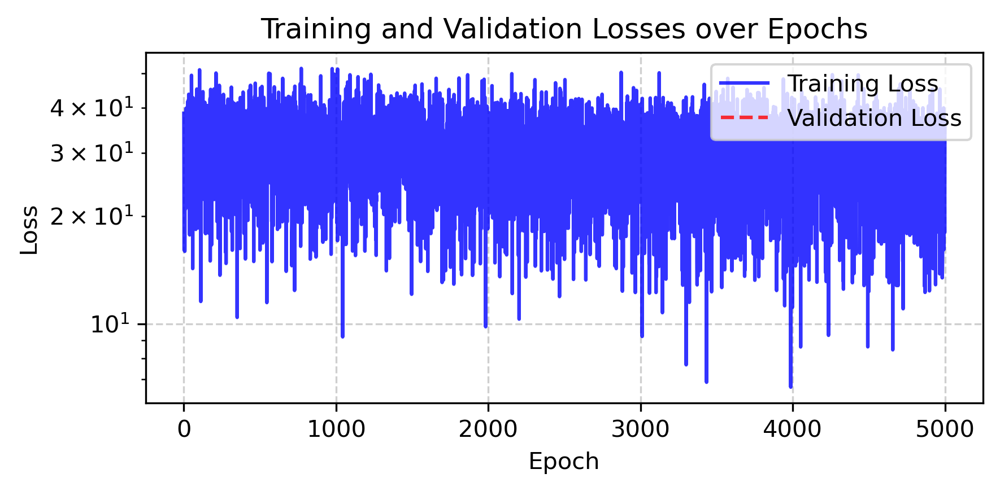

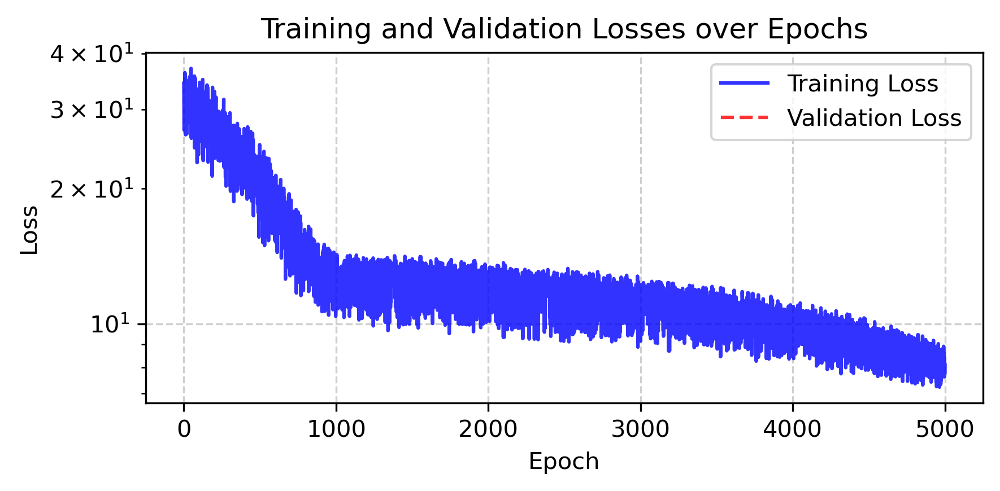

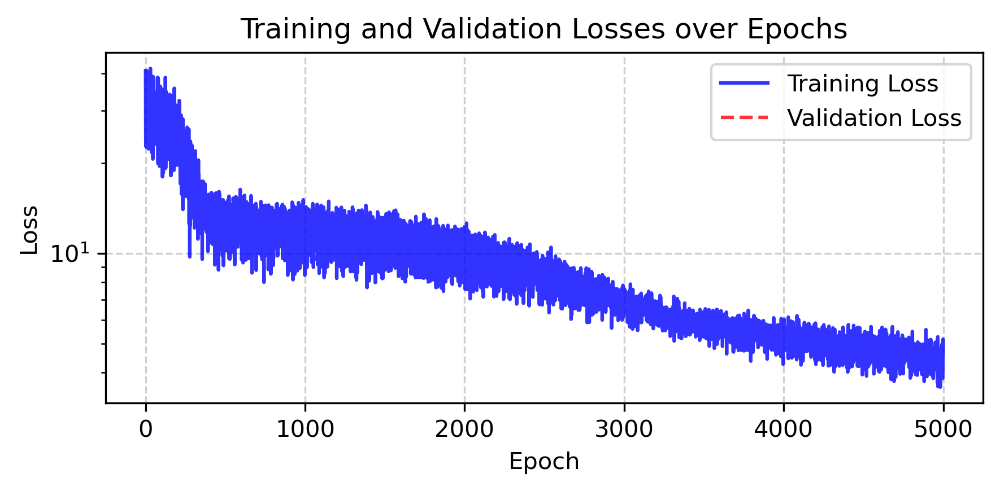

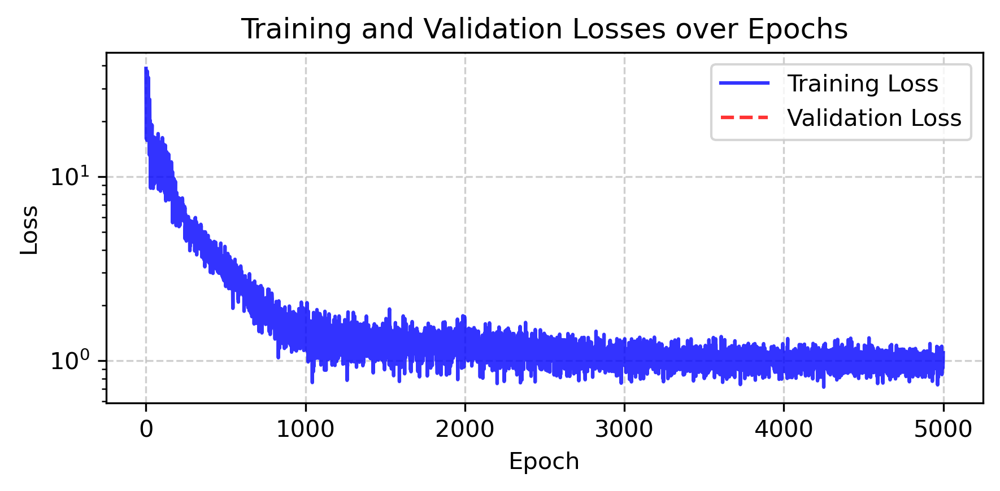

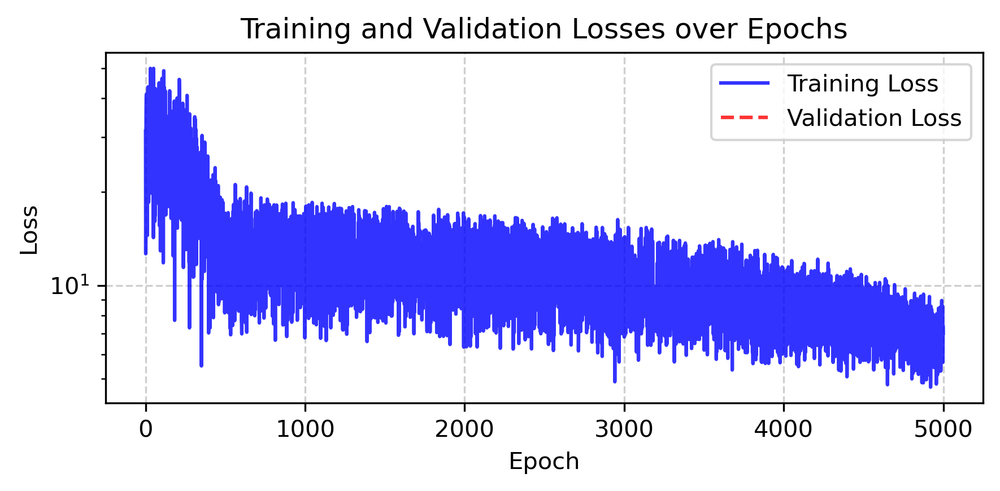

...

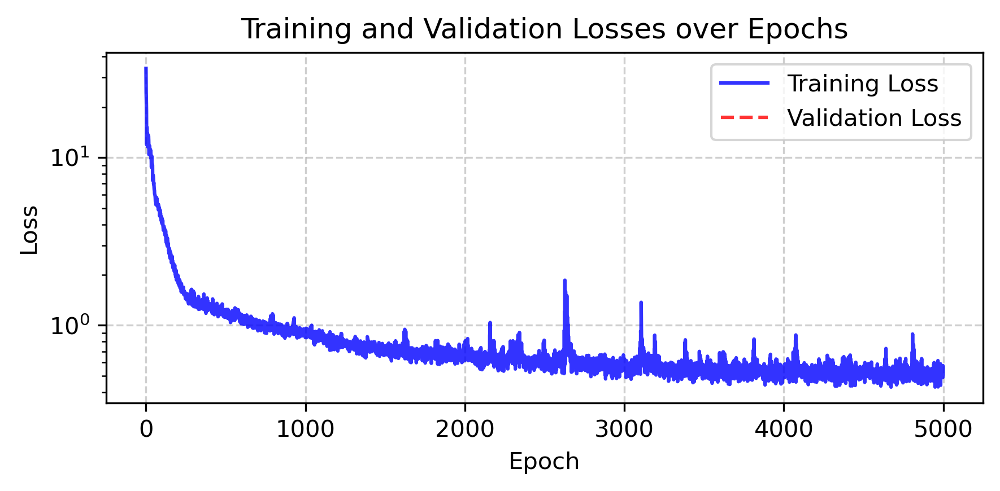

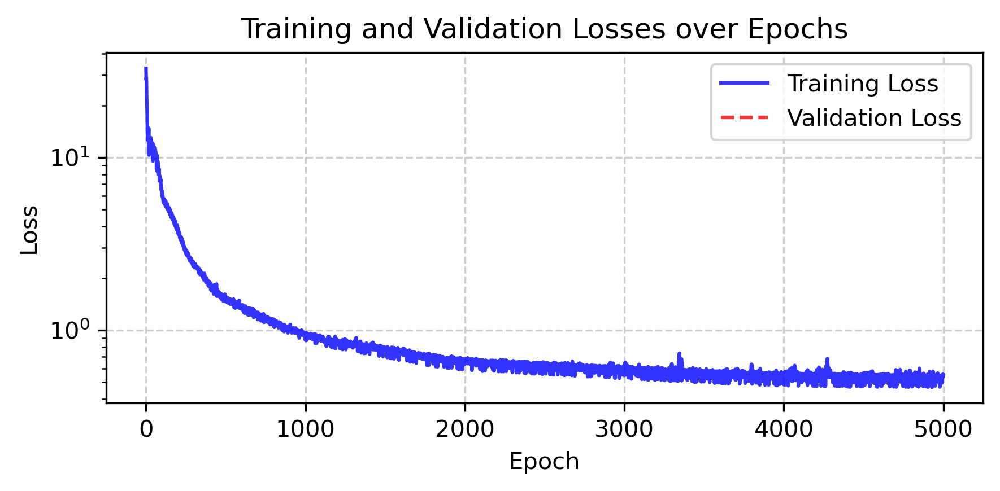

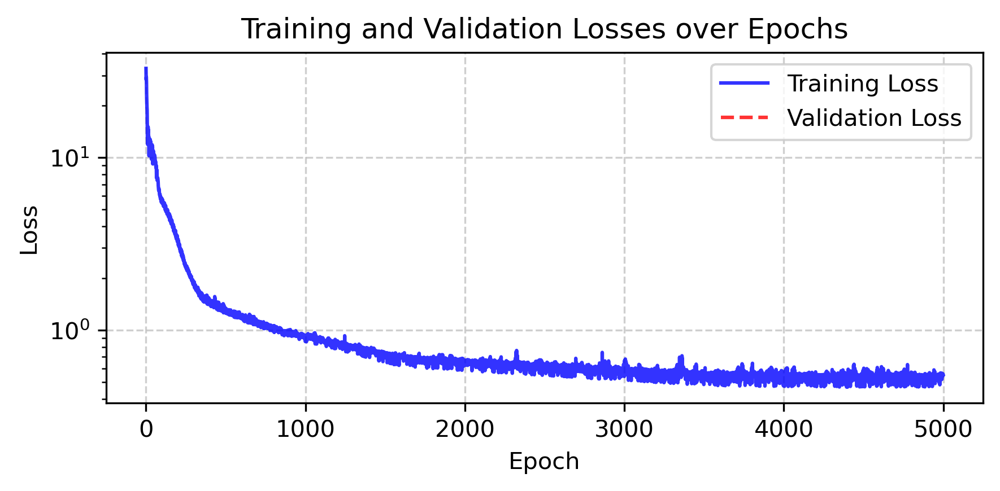

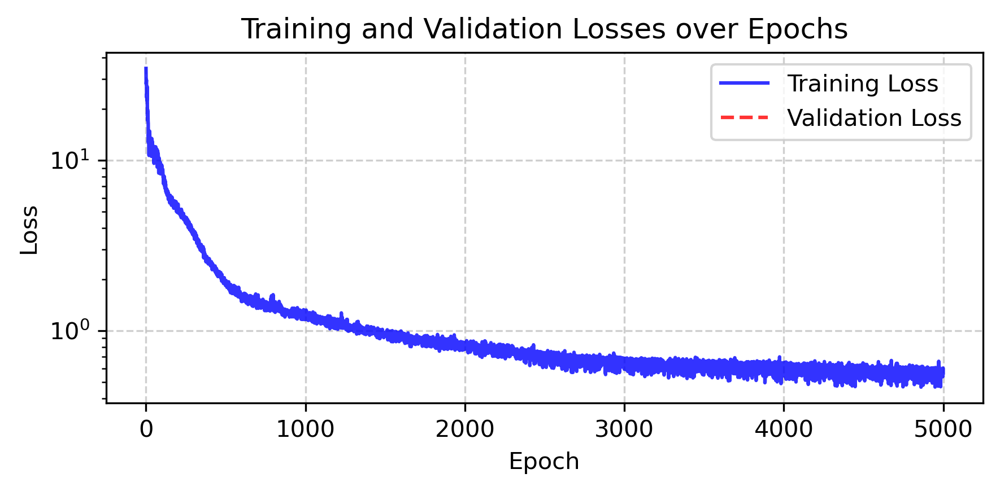

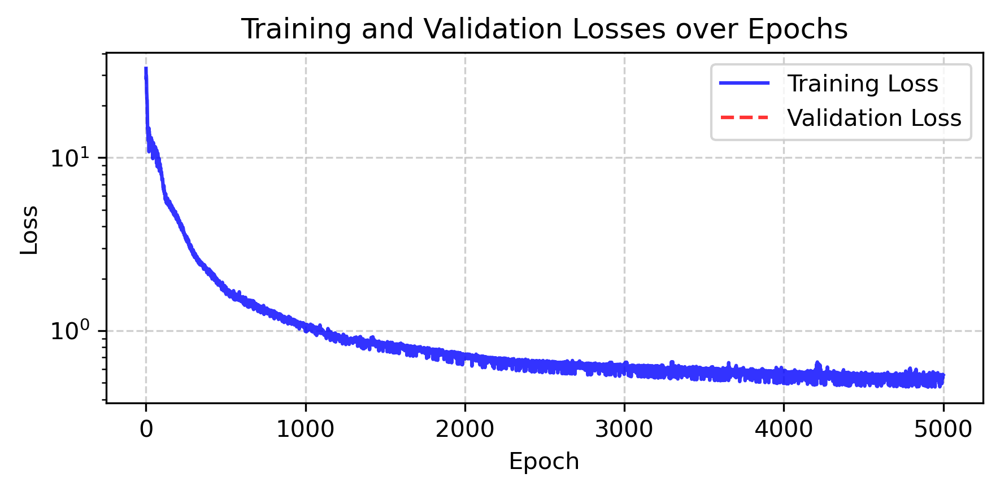

In [19]:
###################################### Cell 17: Optuna optimization ####################################

def count_ffnn_params(input_dim, hidden_layers, output_dim):
    dims = [input_dim] + hidden_layers + [output_dim]

    params = 0
    for i in range(len(dims) - 1):
        params += dims[i] * dims[i + 1]   # weights
        params += dims[i + 1]             # biases

    return params

@torch.compile(fullgraph=False)
def calculate_test_loss(model, true_data, t_Data, v_data, compare_data, target_max, output_max, controls):

    model.eval()  
    testloss, test_r2 = 0, 0
    dim_t = len(t_Data)

    y_true = []
    y_pred = []

    with torch.no_grad(): 
        
        #set initial values of each species for test batches
        state_with_v = torch.cat((true_data[compare_data, 0, :], v_data[compare_data, 0].unsqueeze(1)), dim=1)

        #print(compare_data[:10] if isinstance(compare_data, list) else compare_data)

        #loop ODE system over time points to get predictions
        for i in range(dim_t - 1):

            #solve the ODE to get predicitons
            state_with_v = solve_ode_semi_parametric(
                ode_func=solve_ode,                      #data is normalized here
                state=state_with_v,
                model=model,
                target_max=target_max,
                output_max=output_max,
                controls=controls[compare_data, i, :],
                t=t_Data[i],
                tf=t_Data[i+1],
                h=h)
            
            #extract values without volume
            state_without_v = state_with_v[:, :-1]

            #calculate test loss and r2, summing over time
            testloss = testloss + WMSE(target_data=true_data[compare_data, i+1],
                                         predicted_data=state_without_v,
                                         stds_for_data=stds_for_data[compare_data, i+1])  
            
            #append measured values (no volume)
            y_true.append(true_data[compare_data, i+1])
            #append predicted values (no volume)
            y_pred.append(state_without_v)

    y_true = torch.cat(y_true, dim=0)
    y_pred = torch.cat(y_pred, dim=0)

    y_true_np = y_true.detach().cpu().numpy() / target_max
    y_pred_np = y_pred.detach().cpu().numpy() / target_max

    test_r2 = r2_score(y_true_np.reshape(-1), y_pred_np.reshape(-1))
    testloss = testloss / (dim_t - 1)

    return testloss, test_r2

#prepare data splitting
trainbatches, valbatches = prepare_splits(
    batch_numbers=batch_numbers,
    testbatch=testbatch,
    LOOCV=LOOCV,
    k_folds=k_folds,
    seed=2026)

splits_dict = {
    "trainbatches": trainbatches,
    "valbatches": valbatches,
    "testbatch": testbatch}

best_loss_so_far = [float("inf")]

study_start_time = time.perf_counter()
trial_times = []

def objective(trial):
    trial_seed = 2026 + trial.number
    set_global_seed(trial_seed)

    trial_start_time = time.perf_counter()
    ######################### Hyperparameters to optimize ##########################

    #logarithmic steps
    lr = trial.suggest_float("lr", 1e-5, 1e-2, log=True)

    weight_decay = trial.suggest_float("weight_decay", 1e-7, 1e-3, log=True)

    #with step = 0.05
    weight_dropout_rate = trial.suggest_float("weight_dropout_rate", 0.10, 0.70, step = 0.05)

    train_minibatch_rate = trial.suggest_float("train_minibatch_rate", 0.30, 0.90, step =0.05)

    #with step = 1
    n_hidden_layers = trial.suggest_int("n_hidden_layers", 1, 5)

    n_nodes = trial.suggest_int("n_nodes", 1, 25)

    hidden_layers = [n_nodes] * n_hidden_layers

    if n_hidden_layers == 1:
        activation = 'tanh'                  #activation function 
    else:
        activation = 'relu'

    arch_tag = f"{inputs_num}_{hidden_layers}_{outputs_num}_{method}" 

    if AICc == True:
        #total number of paramters for the model to train
        params_model = count_ffnn_params(inputs_num, hidden_layers, outputs_num)

        #total number of samples for training, validation, and test
        params_total = target_data.numel() - target_data[:,0, 0].numel() * target_data[0, 0, :].numel()
        
    ################################## Run trainings #########################################

    #run fold iterations
    fold_losses = []

    for fold, (trainbatch, valbatch) in enumerate(zip(trainbatches, valbatches)): #these values are correct, these are the right batches

        fold_seed = 2026 + 100*fold
        set_global_seed(fold_seed)

        #create model
        model = FFNN(
            input_dim=inputs_num,
            hidden_layers=hidden_layers,
            output_dim=outputs_num,
            activation=activation
        )

        #optimizer
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

        #weight dropout function
        weight_dropout = weight_dropout_with_precalculated_values(model, weight_dropout_rate)

        #create unique model name 
        tmp_model_name = f"Model_results_{method}_{fold+1}_{arch_tag}_trial_{trial.number}.pt"

        #run training
        predictions, best_train_loss, best_val_loss = train_Hyb_pytorch(
            model=model,
            target_data=target_data,
            target_max=target_max,
            t_Data=time_data,
            v_Data=volume_data,
            optimizer=optimizer,
            n_epochs=epochs,
            train_minibatch_rate=train_minibatch_rate,
            weight_dropout_rate=weight_dropout_rate,
            weight_dropout=weight_dropout,
            trainbatch=trainbatch,
            valbatch=valbatch,
            testbatch=testbatch,
            stds_for_data=stds_for_data,
            output_max=output_max,
            model_name=tmp_model_name,
            run_number= trial.number,
            fold = fold,
            controls=controls_sequence
        )

        if AICc == True:
            #minimize AICc
            checkpoint = torch.load(tmp_model_name)
            model.load_state_dict(checkpoint["model_state_dict"])
            model.eval()

            trainval_batches = trainbatch + valbatch
            print(trainval_batches)
            full_trainval_loss, _ = calculate_test_loss(
                model=model,
                true_data=target_data,
                t_Data=time_data,
                v_data=volume_data,
                compare_data=trainval_batches,
                target_max=target_max,
                output_max=output_max,
                controls=controls_sequence
            )
            
            loss = params_total * math.log(full_trainval_loss) + 2 * params_model + (2 * params_model * (params_model + 1))/(params_total - params_model - 1)

        else:
            #minimize valloss
            loss = best_val_loss 
        
        if np.isnan(loss) or np.isinf(loss):
            return float("inf")

        fold_losses.append(loss)

    #average fold losses (should be the same for AICc because only 1 fold is used)
    mean_loss = float(np.mean(fold_losses))
    
    #warning for AICc:
    if AICc == True:
        if loss != mean_loss:
            print("Warning: Check fold number")
            print(loss)
            print(mean_loss)

    trial_time = time.perf_counter() - trial_start_time

    print(f"Trial time: {trial_time/60:.2f} min")

    return mean_loss

if run_training:
    sampler = optuna.samplers.TPESampler(seed=2026)

    study = optuna.create_study(
        direction="minimize",
        study_name="Hybrid_Optimization",
        sampler=sampler)

    pbar = tqdm(total=N_TRIALS)

    def callback(study, trial):
        pbar.update(1)

    study.optimize(objective, n_trials=N_TRIALS, callbacks=[callback])

    pbar.close()

    best_params = study.best_params
    best_hidden_layers = [best_params["n_nodes"]] * best_params["n_hidden_layers"]
    best_activation = ("tanh" if best_params["n_hidden_layers"] == 1 else "relu")

    print("\n================ BEST TRIAL ================")
    print(f"Best loss: {study.best_value}")

    print("\nBest parameters:")

    for key, value in study.best_params.items():
        print(f"{key}: {value}")
else: 
    print("Skipped Optuna optimization.")
    

Best activation function: tanh
26_[2]_25_AICc
Trial 45, Fold 0: Trainloss - 0.4157; Valloss - nan
Fold 0: Trainloss: 0.4157, Valloss: nan


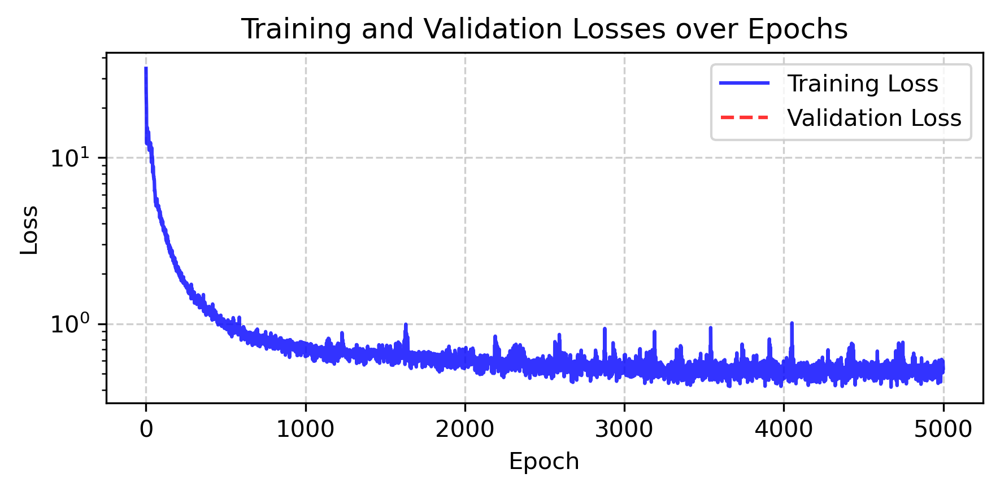

In [20]:
################################## Cell 18: Final retraining or Model training ####################################

if run_training:
    lr = best_params["lr"]
    weight_decay = best_params["weight_decay"]
    weight_dropout_rate = best_params["weight_dropout_rate"]
    train_minibatch_rate = best_params["train_minibatch_rate"]
    n_hidden_layers = best_params["n_hidden_layers"]
    n_nodes = best_params["n_nodes"]
    best_trial_num = study.best_trial.number 

else:
    best_params = {"lr": 0.0040447, "weight_decay": 1.899864e-05, "weight_dropout_rate": 0.15, "train_minibatch_rate": 0.90, "n_hidden_layers": 1, "n_nodes": 2, "activation": 'tanh', "best_trial_num": 47}
    best_trial_num = best_params["best_trial_num"]

    best_trial_num = best_params["best_trial_num"]

best_activation = ("tanh" if best_params["n_hidden_layers"] == 1 else "relu")
activation = best_activation
print(f"Best activation function: {best_activation}")

nh = ([n_nodes] * n_hidden_layers if run_training
      else [best_params["n_nodes"]] * best_params["n_hidden_layers"])

arch_tag = f"{inputs_num}_{nh}_{outputs_num}_{method}" 
print(arch_tag)  

final_fold_models = []

trainbatches, valbatches = prepare_splits(
    batch_numbers=batch_numbers,
    testbatch=testbatch,
    LOOCV=LOOCV,
    k_folds=k_folds,
    seed=2026)

splits_dict = {
    "trainbatches": trainbatches,
    "valbatches": valbatches,
    "testbatch": testbatch}

for fold, (trainbatch, valbatch) in enumerate(zip(trainbatches, valbatches)):
    fold_seed = 2026 + 100*fold
    set_global_seed(fold_seed)
    
    model = FFNN(
        input_dim=inputs_num,
        hidden_layers=nh,
        output_dim=outputs_num,
        activation=best_activation)

    optimizer = torch.optim.AdamW(model.parameters(), lr=best_params["lr"], weight_decay=best_params["weight_decay"])

    weight_dropout = weight_dropout_with_precalculated_values(model, best_params["weight_dropout_rate"])

    final_model_name = f"Model_results_{fold+1}_{arch_tag}.pt"

    best_hparams = {
        "lr": best_params["lr"],
        "weight_decay": best_params["weight_decay"],
        "weight_dropout_rate": best_params["weight_dropout_rate"],
        "train_minibatch_rate": best_params["train_minibatch_rate"],
        "n_hidden_layers": best_params["n_hidden_layers"],
        "n_nodes": best_params["n_nodes"],
        "activation": best_activation,
        "hidden_layers": nh,
        "best_trial_num": best_trial_num if run_training else best_params["best_trial_num"]}

    predictions, train_loss, val_loss = train_Hyb_pytorch(
        model=model,
        target_data=target_data,
        target_max=target_max,
        t_Data=time_data,
        v_Data=volume_data,
        optimizer=optimizer,
        n_epochs=epochs,
        train_minibatch_rate=best_params["train_minibatch_rate"],
        weight_dropout_rate=best_params["weight_dropout_rate"],
        weight_dropout=weight_dropout,
        trainbatch=trainbatch,
        valbatch=valbatch,
        testbatch=testbatch,
        stds_for_data=stds_for_data,
        output_max=output_max,
        controls=controls_sequence,
        model_name=final_model_name,
        run_number= best_trial_num if run_training else best_params["best_trial_num"],
        fold = fold)

    checkpoint = torch.load(final_model_name)

    checkpoint["best_hparams"] = best_hparams

    torch.save(checkpoint, final_model_name)

    print(f"Fold {fold}: Trainloss: {round(train_loss,4)}, Valloss: {round(val_loss,4)}")

    final_fold_models.append(final_model_name)


26_[2]_25_AICc


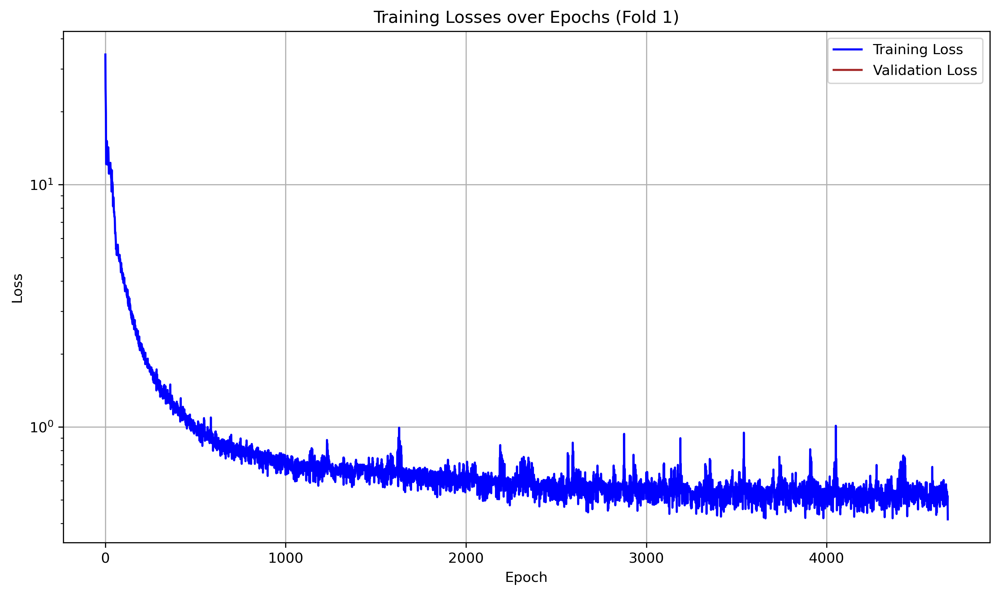

In [22]:
########################## Cell 19: Plot Validation and Training losses ######################
run_training = False  
print(arch_tag) 
best_activation = ("tanh" if best_params["n_hidden_layers"] == 1 else "relu")
activation = best_activation 

trainbatches, valbatches = prepare_splits(
    batch_numbers=batch_numbers,
    testbatch=testbatch,
    LOOCV=LOOCV,
    k_folds=k_folds,
    seed=2026)

splits_dict = {
    "trainbatches": trainbatches,
    "valbatches": valbatches,
    "testbatch": testbatch}

batches_split = (trainbatches, valbatches)
        
trainbatches, valbatches = batches_split
num_files = len(valbatches)

for fold in range(num_files):
    if run_training:
        model_name = f"Model_results_{fold+1}_{arch_tag}_trial_{best_trial_num}.pt"
    else:
        model_name = f"Model_results_{fold+1}_{arch_tag}.pt"

    model = FFNN(input_dim=inputs_num, hidden_layers=nh, output_dim=outputs_num, activation=activation)
    checkpoint = torch.load(model_name)

    trainloss_list = [x.item() if isinstance(x, torch.Tensor) else x for x in checkpoint['trainloss_list']]
    valloss_list  = [x.item() if isinstance(x, torch.Tensor) else x for x in checkpoint['valloss_list']]

    plt.figure(figsize=(10, 6), dpi=300)
    plt.plot(trainloss_list, label="Training Loss", color="blue")
    plt.plot(valloss_list, label="Validation Loss", color="brown")
    plt.yscale("log")
    plt.legend()
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training Losses over Epochs (Fold {fold+1})")
    plt.grid()
    plt.tight_layout()
    if run_training:
        plt.show()
    else:
        plt.show()

In [23]:
################################# Cell 20: Test loss calculation ###############################
print(arch_tag)

model_paths = final_fold_models

def to_float(x):
    return float(x.detach()) if isinstance(x, torch.Tensor) else float(x)
    
def calculate_ensemble_loss(models_paths, true_data, t_Data, v_data, compare_data,
                            target_max, output_max, controls):

    dim_t = len(t_Data)
    n_models = len(models_paths)

    with torch.no_grad():
        
        y_pred_sum = None

        for model_path in models_paths:
            checkpoint = torch.load(model_path)

            net = FFNN(
                input_dim=inputs_num,
                hidden_layers=nh,
                output_dim=outputs_num,
                activation=activation
            )
            
            net.load_state_dict(checkpoint["model_state_dict"])
            net.eval()

            state_with_v = torch.cat((true_data[compare_data, 0, :],
                                      v_data[compare_data, 0].unsqueeze(1)), dim=1)

            preds = []

            for i in range(dim_t - 1):

                state_with_v = solve_ode_semi_parametric(
                    ode_func=solve_ode,
                    state=state_with_v,
                    model=net,
                    target_max=target_max,
                    output_max=output_max,
                    controls=controls[compare_data, i, :],
                    t=t_Data[i],
                    tf=t_Data[i+1],
                    h=h
                )

                preds.append(state_with_v[:, :-1])

            preds = torch.stack(preds)  # (time-1, batch, species)

            y_pred_sum = preds if y_pred_sum is None else (y_pred_sum + preds)

        #average predictions
        y_pred_avg = y_pred_sum / n_models

        y_true = []
        testloss = 0

        ######################## Compute errors for average predictions ######################

        # build true values
        for i in range(dim_t - 1):
            y_true.append(true_data[compare_data, i+1])

            testloss += WMSE(
                target_data=y_true[i],
                predicted_data=y_pred_avg[i],
                stds_for_data=stds_for_data[compare_data, i+1]
            )

        y_true = torch.cat(y_true, dim=0)
        y_pred = y_pred_avg.reshape(-1, y_pred_avg.shape[-1])

        y_true_np = y_true.detach().cpu().numpy() / target_max
        y_pred_np = y_pred.detach().cpu().numpy() / target_max

        test_r2 = r2_score(y_true_np.reshape(-1), y_pred_np.reshape(-1))

        testloss = testloss / (dim_t - 1)

    return testloss, test_r2

#calculate loss for test batches using model
@torch.compile(fullgraph=False)
def calculate_test_loss(model, true_data, t_Data, v_data, compare_data, target_max, output_max, controls):

    model.eval()  
    testloss, test_r2 = 0, 0
    dim_t = len(t_Data)

    y_true = []
    y_pred = []

    with torch.no_grad(): 
        
        #set initial values of each species for test batches
        state_with_v = torch.cat((true_data[compare_data, 0, :], v_data[compare_data, 0].unsqueeze(1)), dim=1)

        #print(compare_data[:10] if isinstance(compare_data, list) else compare_data)

        #loop ODE system over time points to get predictions
        for i in range(dim_t - 1):

            #solve the ODE to get predicitons
            state_with_v = solve_ode_semi_parametric(
                ode_func=solve_ode,                      #data is normalized here
                state=state_with_v,
                model=model,
                target_max=target_max,
                output_max=output_max,
                controls=controls[compare_data, i, :],
                t=t_Data[i],
                tf=t_Data[i+1],
                h=h)
            
            #extract values without volume
            state_without_v = state_with_v[:, :-1]

            #calculate test loss and r2, summing over time
            testloss = testloss + WMSE(target_data=true_data[compare_data, i+1],
                                         predicted_data=state_without_v,
                                         stds_for_data=stds_for_data[compare_data, i+1])  
            
            #append measured values (no volume)
            y_true.append(true_data[compare_data, i+1])
            #append predicted values (no volume)
            y_pred.append(state_without_v)

    y_true = torch.cat(y_true, dim=0)
    y_pred = torch.cat(y_pred, dim=0)

    y_true_np = y_true.detach().cpu().numpy() / target_max
    y_pred_np = y_pred.detach().cpu().numpy() / target_max

    test_r2 = r2_score(y_true_np.reshape(-1), y_pred_np.reshape(-1))
    testloss = testloss / (dim_t - 1)

    return testloss, test_r2

###################################### Calculate per fold results  ###############################

trainbatches, valbatches = batches_split
results_list = []

num_models = len(trainbatches)

for fold in range(num_models):
    trainbatch = trainbatches[fold]
    valbatch   = valbatches[fold]
        
    model = FFNN(
        input_dim=inputs_num,
        hidden_layers=nh,
        output_dim=outputs_num,
        activation=activation
    )
    
    checkpoint = torch.load(model_paths[fold])
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    with torch.no_grad():
        if testbatch !=[]:
            test_loss, test_r2 = calculate_test_loss(
                model=model,
                true_data=target_data,
                t_Data=time_data,
                v_data=volume_data,
                compare_data=testbatch,
                target_max=target_max,
                output_max=output_max,
                controls=controls_sequence
            )

        best_train_loss, train_r2 = calculate_test_loss(
            model=model,
            true_data=target_data,
            t_Data=time_data,
            v_data=volume_data,
            compare_data=trainbatch,
            target_max=target_max,
            output_max=output_max,
            controls=controls_sequence
        )

        if len(valbatch) > 0:
            best_val_loss, val_r2 = calculate_test_loss(
                model=model,
                true_data=target_data,
                t_Data=time_data,
                v_data=volume_data,
                compare_data=valbatch,
                target_max=target_max,
                output_max=output_max,
                controls=controls_sequence
            )

        else:
            best_val_loss = np.nan
            val_r2 = np.nan

    results_list.append([
        fold+1,
        to_float(best_train_loss),
        to_float(train_r2),
        to_float(best_val_loss),
        to_float(val_r2),
        to_float(test_loss),
        to_float(test_r2)
    ])

results = np.array(results_list, dtype=object)

############################ Calculate Averaged results ############################

train_losses = np.array([r[1] for r in results], dtype=float)
val_losses   = np.array([r[3] for r in results], dtype=float)
if testbatch != []:
    test_losses  = np.array([r[5] for r in results], dtype=float)

train_r2s = np.array([r[2] for r in results], dtype=float)
val_r2s   = np.array([r[4] for r in results], dtype=float)
if testbatch != []:
    test_r2s  = np.array([r[6] for r in results], dtype=float)

mean_train_loss, sd_train_loss = train_losses.mean(), train_losses.std()
mean_val_loss,   sd_val_loss   = val_losses.mean(), val_losses.std()
if testbatch != []:
    mean_test_loss,  sd_test_loss  = test_losses.mean(), test_losses.std()

mean_train_r2 = train_r2s.mean()
mean_val_r2   = val_r2s.mean()
if testbatch != []:
    mean_test_r2  = test_r2s.mean()

############################ Calculate Enssembled results  ############################

train_batches = [b for b in batch_numbers if b not in testbatch]

train_loss_ens, train_r2_ens = calculate_ensemble_loss(
    models_paths=model_paths,
    true_data=target_data,
    t_Data=time_data,
    v_data=volume_data,
    compare_data=train_batches,
    target_max=target_max,
    output_max=output_max,
    controls=controls_sequence
)

#get test predictions
if testbatch != []:
    test_loss_ens, test_r2_ens = calculate_ensemble_loss(
        models_paths=model_paths,
        true_data=target_data,
        t_Data=time_data,
        v_data=volume_data,
        compare_data=testbatch,
        target_max=target_max,
        output_max=output_max,
        controls=controls_sequence
    )

#per fold results
#print("\n=============================== Per-fold results =======================")
print("\n||          ||       Training      ||      Validation     ||        Test         ||")
print("||   Fold   ||   WMSE   |    R2    ||   WMSE   |    R2    ||   WMSE   |    R2    ||")

for row in results:
    print(
        f"|| {row[0]:^7}  || "
        f"{row[1]:^8.4f} | {row[2]:^8.4f} || "
        f"{row[3]:^8.4f} | {row[4]:^8.4f} || "
        f"{row[5]:^8.4f} | {row[6]:^8.4f} ||"
    )

#average results of folds
#print("\n================================== Mean ± STD ==========================")
print(
    f"||   WMSE   ||"
    f"  {mean_train_loss:^8.4f}±{sd_train_loss:^8.4f}  ||"
    f"  {mean_val_loss:^8.4f}±{sd_val_loss:^8.4f}  ||"
    f"  {mean_test_loss:^8.4f}±{sd_test_loss:^8.4f}  ||"
)

print(
    f"||    R2    ||"
    f"{mean_train_r2:^20.4f} ||"
    f"{mean_val_r2:^20.4f} ||"
    f"{mean_test_r2:^20.4f} ||"
)

#ensemble results
#print("\n=============================== Ensemeble results ======================")
print( "\n|| Ensemble ||   Train WMSE  |   Train R2   ||  Test WMSE   |   Test R2    ||")
print(
    f"||          || "
    f"{train_loss_ens:^14.4f}|{train_r2_ens:^14.4f}||"
    f"{test_loss_ens:^14.4f}|{test_r2_ens:^14.4f}||"
)

#total number of paramters for the model to train
params_model = count_ffnn_params(inputs_num, nh, outputs_num)
#total number of samples for training, validation, and test
params_total = target_data.numel() - target_data[:,0, 0].numel() * target_data[0, 0, :].numel()
print(params_model, params_total)

loss = params_total * math.log(mean_train_loss) + 2 * params_model + (2 * params_model * (params_model + 1))/(params_total - params_model - 1)
print(loss)
#0.6479

26_[2]_25_AICc

||          ||       Training      ||      Validation     ||        Test         ||
||   Fold   ||   WMSE   |    R2    ||   WMSE   |    R2    ||   WMSE   |    R2    ||
||    1     ||  0.5095  |  0.9450  ||   nan    |   nan    ||  2.0368  |  0.9193  ||
||   WMSE   ||   0.5095 ± 0.0000   ||    nan   ±  nan     ||   2.0368 ± 0.0000   ||
||    R2    ||       0.9450        ||        nan          ||       0.9193        ||

|| Ensemble ||   Train WMSE  |   Train R2   ||  Test WMSE   |   Test R2    ||
||          ||     0.5095    |    0.9450    ||    2.0368    |    0.9193    ||
129 7500
-4794.426169978998


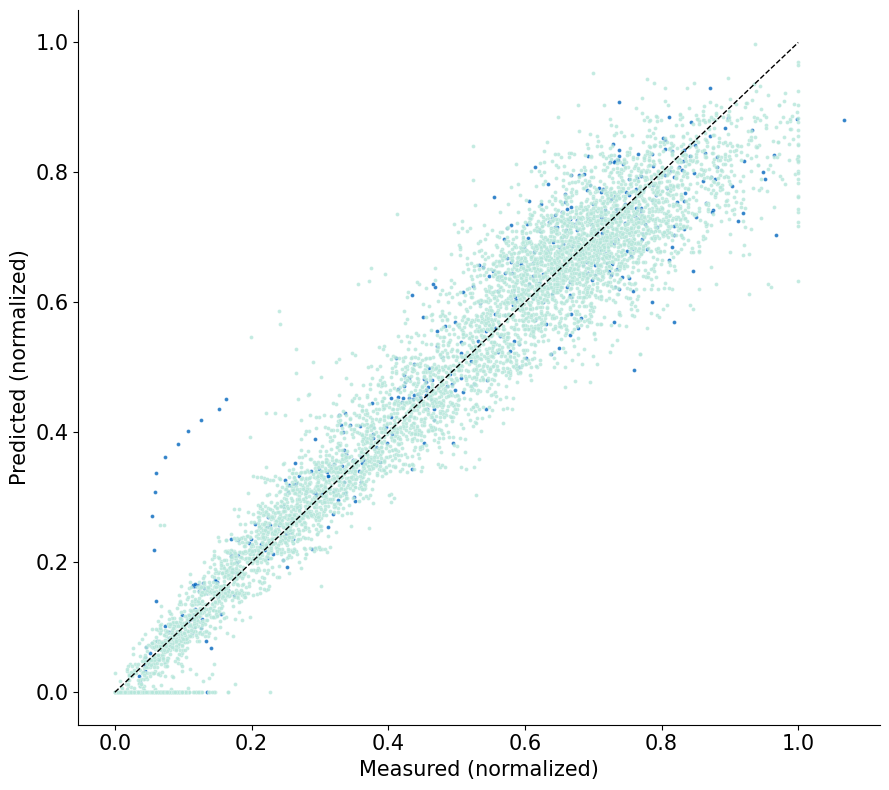

In [24]:
############################### Cell 21: Parity Plot ######################################

best_activation = ("tanh" if best_params["n_hidden_layers"] == 1 else "relu")
activation = best_activation 

################################ Build model paths by name, not by relying on final_fold_models in memory ################################

trainbatches, valbatches = prepare_splits(
    batch_numbers=batch_numbers,
    testbatch=testbatch,
    LOOCV=LOOCV,
    k_folds=k_folds,
    seed=2026)

if run_training:
    model_paths = [f"Model_results_{i+1}_{arch_tag}_trial_{best_trial_num}.pt" for i in range(len(trainbatches))]
else:
    model_paths = [f"Model_results_{i+1}_{arch_tag}.pt" for i in range(len(trainbatches))]

@torch.compile(fullgraph=False)
def get_ensemble_predictions_for_batches(models_paths, target_data, t_Data, v_data, batches,
                                         target_max, output_max, controls):

    dim_t = len(t_Data)
    n_models = len(models_paths)

    measured_list = []
    pred_sum = None

    with torch.no_grad():

        ######################## Ensemble predictions ########################
        for model_path in models_paths:

            checkpoint = torch.load(model_path)

            net = FFNN(
                input_dim=inputs_num,
                hidden_layers=nh,
                output_dim=outputs_num,
                activation=activation )
            
            net.load_state_dict(checkpoint["model_state_dict"])
            net.eval()

            state_with_v = torch.cat(
                (target_data[batches, 0, :],
                 v_data[batches, 0].unsqueeze(1)), dim=1)

            preds = []

            for i in range(dim_t - 1):

                state_with_v = solve_ode_semi_parametric(
                    ode_func=solve_ode,
                    state=state_with_v,
                    model=net,   
                    target_max=target_max,
                    output_max=output_max,
                    controls=controls[batches, i, :],
                    t=t_Data[i],
                    tf=t_Data[i+1],
                    h=h)

                preds.append((state_with_v[:, :-1] / target_max).cpu().numpy())

            preds = np.array(preds)  # (time-1, batch, species)

            pred_sum = preds if pred_sum is None else (pred_sum + preds)

        pred_avg = pred_sum / n_models

        ######################## Measured values ########################
        for i in range(dim_t - 1):
            meas = (target_data[batches, i+1] / target_max).numpy()
            measured_list.append(meas)

        measured_arr = np.array(measured_list)

    return measured_arr, pred_avg

trainval_batches = [b for b in batch_numbers if b not in testbatch]

#get train predictions
train_meas, train_pred = get_ensemble_predictions_for_batches(
    models_paths=model_paths,
    target_data=target_data,
    t_Data=time_data,
    v_data=volume_data,
    batches=trainval_batches,
    target_max=target_max,
    output_max=output_max,
    controls=controls_sequence
)

#get test predictions
test_meas, test_pred = get_ensemble_predictions_for_batches(
    models_paths=model_paths,
    target_data=target_data,
    t_Data=time_data,
    v_data=volume_data,
    batches=testbatch,
    target_max=target_max,
    output_max=output_max,
    controls=controls_sequence
)

test_color = "#0065BD"
train_color = "#B4E6DA"# "#BFE2A8" #"#BFE2A8" #"#B4E6DA"# "#BFE2A8"

fig, ax = plt.subplots(figsize=(9, 8))
ax.scatter(test_meas.reshape(-1), test_pred.reshape(-1), s=8, alpha=0.80, color=test_color,
           edgecolors="white", linewidths=0.2, label='Testing', zorder=1)
ax.scatter(train_meas.reshape(-1), train_pred.reshape(-1), s=8, alpha=0.80, color=train_color,
           edgecolors="white", linewidths=0.2, label='Training', zorder=2)



#parity line only
ax.plot([0, 1], [0, 1], 'k--', lw=1.0, zorder=3)

ax.set_xlabel("Measured (normalized)", fontsize=15)
ax.set_ylabel("Predicted (normalized)", fontsize=15)
ax.tick_params(axis='both', labelsize=15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
#ax.legend(fontsize=15)

plt.tight_layout()
plt.show()

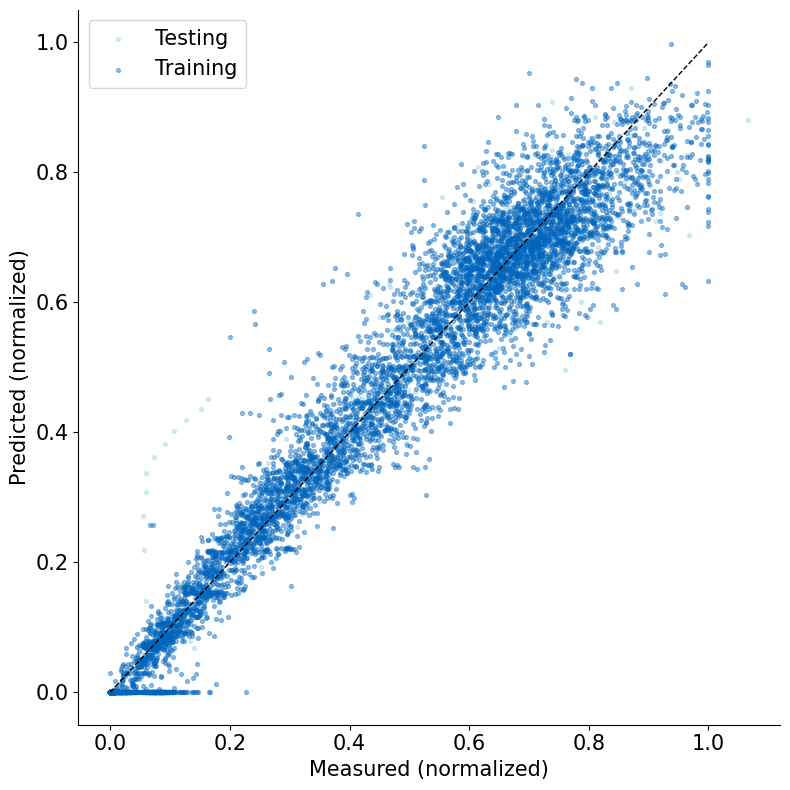

In [25]:
############################### Cell 22: Parity Plot ######################################

model_paths = final_fold_models
best_activation = ("tanh" if best_params["n_hidden_layers"] == 1 else "relu")
activation = best_activation 

@torch.compile(fullgraph=False)
def get_ensemble_predictions_for_batches(models_paths, target_data, t_Data, v_data, batches,
                                         target_max, output_max, controls):

    dim_t = len(t_Data)
    n_models = len(models_paths)

    measured_list = []
    pred_sum = None

    with torch.no_grad():

        ######################## Ensemble predictions ########################
        for model_path in models_paths:

            checkpoint = torch.load(model_path)

            net = FFNN(
                input_dim=inputs_num,
                hidden_layers=nh,
                output_dim=outputs_num,
                activation=activation )
            
            net.load_state_dict(checkpoint["model_state_dict"])
            net.eval()

            state_with_v = torch.cat(
                (target_data[batches, 0, :],
                 v_data[batches, 0].unsqueeze(1)), dim=1)

            preds = []

            for i in range(dim_t - 1):

                state_with_v = solve_ode_semi_parametric(
                    ode_func=solve_ode,
                    state=state_with_v,
                    model=net,   
                    target_max=target_max,
                    output_max=output_max,
                    controls=controls[batches, i, :],
                    t=t_Data[i],
                    tf=t_Data[i+1],
                    h=h)

                preds.append((state_with_v[:, :-1] / target_max).cpu().numpy())

            preds = np.array(preds)  # (time-1, batch, species)

            pred_sum = preds if pred_sum is None else (pred_sum + preds)

        pred_avg = pred_sum / n_models

        ######################## Measured values ########################
        for i in range(dim_t - 1):
            meas = (target_data[batches, i+1] / target_max).numpy()
            measured_list.append(meas)

        measured_arr = np.array(measured_list)

    return measured_arr, pred_avg

trainval_batches = [b for b in batch_numbers if b not in testbatch]

#get train predictions
train_meas, train_pred = get_ensemble_predictions_for_batches(
    models_paths=model_paths,
    target_data=target_data,
    t_Data=time_data,
    v_data=volume_data,
    batches=trainval_batches,
    target_max=target_max,
    output_max=output_max,
    controls=controls_sequence
)

#get test predictions
test_meas, test_pred = get_ensemble_predictions_for_batches(
    models_paths=model_paths,
    target_data=target_data,
    t_Data=time_data,
    v_data=volume_data,
    batches=testbatch,
    target_max=target_max,
    output_max=output_max,
    controls=controls_sequence
)

train_color = "#0065BD"
test_color  = "#95D1E2"

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(test_meas.reshape(-1), test_pred.reshape(-1), s=8, alpha=0.40, color=test_color, label='Testing', zorder=1)
ax.scatter(train_meas.reshape(-1), train_pred.reshape(-1), s=8, alpha=0.40, color=train_color, label='Training', zorder=2)

#parity line only
ax.plot([0, 1], [0, 1], 'k--', lw=1.0, zorder=3)

ax.set_xlabel("Measured (normalized)", fontsize=15)
ax.set_ylabel("Predicted (normalized)", fontsize=15)
ax.tick_params(axis='both', labelsize=15)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(fontsize=15)

plt.tight_layout()
plt.show()



In [31]:
################################################ Cell 23: True vs Predicted, True vs Noisy ################################

########################################################## Prepare True Data ##############################################
print(arch_tag)
print()

#full model batch indices
trainval_batches = [b for b in batch_numbers if b not in testbatch]

if run_training:
    model_paths = [f"Model_results_{i+1}_{arch_tag}_trial_{best_trial_num}.pt" for i in range(len(trainbatches))]
else:
    model_paths = [f"Model_results_{i+1}_{arch_tag}.pt" for i in range(len(trainbatches))]
     
@torch.compile(fullgraph=False)
def calculate_metrics_vs_true(true_data, compare_data, stds_for_data, batches):

    testloss, test_r2 = 0, 0
    dim_t = true_data.shape[1]

    y_true = []
    y_pred = []

    with torch.no_grad(): 
        #loop ODE system over time points to get predictions
        for i in range(dim_t - 1):

            #calculate test loss and r2, summing over time
            testloss += WMSE(
                target_data=true_data[batches, i+1],
                predicted_data=compare_data[batches, i+1],
                stds_for_data=stds_for_data[batches, i+1])
            
            #append measured values (no volume)
            y_true.append(true_data[batches, i+1])
            #append predicted values (no volume)
            y_pred.append(compare_data[batches, i+1])

    y_true = torch.cat(y_true, dim=0)
    y_pred = torch.cat(y_pred, dim=0)
    y_true_np = y_true.detach().cpu().numpy() / target_max
    y_pred_np = y_pred.detach().cpu().numpy() / target_max
    test_r2 = r2_score(y_true_np.reshape(-1), y_pred_np.reshape(-1))
    testloss = testloss / (dim_t - 1)

    return testloss, test_r2

################################# Noisy vs True #######################################

#for training and validation
noisy_vs_true_trainval_wmse, noisy_vs_true_trainval_r2 = calculate_metrics_vs_true(
    true_data=true_data,
    compare_data=target_data,
    stds_for_data=stds_for_data,
    batches=trainval_batches)

#for testing
if testbatch != []:
    noisy_vs_true_test_wmse, noisy_vs_true_test_r2 = calculate_metrics_vs_true(
        true_data=true_data,
        compare_data=target_data,
        stds_for_data=stds_for_data,
        batches=testbatch)

################################# Predicted vs True ####################################

#TRAIN+VAL predictions (ensemble) 
meas_trainval, pred_trainval = get_ensemble_predictions_for_batches(
    models_paths=model_paths,
    target_data=target_data,
    t_Data=time_data,
    v_data=volume_data,
    batches=trainval_batches,
    target_max=target_max,
    output_max=output_max,
    controls=controls_sequence
)

pred_trainval = torch.from_numpy(pred_trainval) * target_max

pred_full_trainval = true_data.clone()
for j, b in enumerate(trainval_batches):
    pred_full_trainval[b, 1:, :] = pred_trainval[:, j, :]


#TEST predictions (ensemble) 
if testbatch != []:
    meas_test, pred_test = get_ensemble_predictions_for_batches(
        models_paths=model_paths,
        target_data=target_data,
        t_Data=time_data,
        v_data=volume_data,
        batches=testbatch,
        target_max=target_max,
        output_max=output_max,
        controls=controls_sequence
    )

    pred_test = torch.from_numpy(pred_test) * target_max

    pred_full_test = true_data.clone()
    for j, b in enumerate(testbatch):
        pred_full_test[b, 1:, :] = pred_test[:, j, :]

############################################ Metrics ##################################

#train+Val vs True
pred_vs_true_trainval_wmse, pred_vs_true_trainval_r2 = calculate_metrics_vs_true(
    true_data=true_data,
    compare_data=pred_full_trainval,
    stds_for_data=stds_for_data,
    batches=trainval_batches
)

#train+Val vs Noisy
pred_vs_noisy_trainval_wmse, pred_vs_noisy_trainval_r2 = calculate_metrics_vs_true(
    true_data=target_data,
    compare_data=pred_full_trainval,
    stds_for_data=stds_for_data,
    batches=trainval_batches
)

#test vs True
if testbatch != []:
    pred_vs_true_test_wmse, pred_vs_true_test_r2 = calculate_metrics_vs_true(
        true_data=true_data,
        compare_data=pred_full_test,
        stds_for_data=stds_for_data,
        batches=testbatch
    )

#test vs Noisy
if testbatch != []:
    pred_vs_noisy_test_wmse, pred_vs_noisy_test_r2 = calculate_metrics_vs_true(
        true_data=target_data,
        compare_data=pred_full_test,
        stds_for_data=stds_for_data,
        batches=testbatch
    )

#asemble metrics table
records = []

def add_row(dataset, comparison, wmse, r2):
    records.append({
        "Dataset": dataset,
        "Comparison": comparison,
        "WMSE": wmse,
        "R2": r2
    })

#baseline
add_row("Train+Val", "Noisy vs True", noisy_vs_true_trainval_wmse, noisy_vs_true_trainval_r2)
add_row("Test", "Noisy vs True", noisy_vs_true_test_wmse, noisy_vs_true_test_r2)

#model results
add_row("\nTrain+Val ", "Pred vs Noisy", pred_vs_noisy_trainval_wmse, pred_vs_noisy_trainval_r2)
add_row("Test", "Pred vs Noisy", pred_vs_noisy_test_wmse, pred_vs_noisy_test_r2)

add_row("\nTrain+Val ", "Pred vs True", pred_vs_true_trainval_wmse, pred_vs_true_trainval_r2)
add_row("Test", "Pred vs True", pred_vs_true_test_wmse, pred_vs_true_test_r2)

header = (f"{'Dataset':<10} | {'Comparison':<15} | {'WMSE':^8} | {'R²':^8}")

#print table
print(header)
print("-" * len(header))

for r in records:
    print(f"{r['Dataset']:<10} | {r['Comparison']:<15} | {r['WMSE']:^8.4f} | {r['R2']:^8.4f}")

#26_[2]_25_AICc
#Dataset    | Comparison      |   WMSE   |    R²   
#--------------------------------------------------
#Train+Val  | Noisy vs True   |  0.4696  |  0.9622 
#Test       | Noisy vs True   |  0.6363  |  0.9591 

#Train+Val  | Pred vs Noisy   |  0.5095  |  0.9450 
#Test       | Pred vs Noisy   |  2.0368  |  0.9193 

#Train+Val  | Pred vs True    |  0.0908  |  0.9802 
#Test       | Pred vs True    |  0.9234  |  0.9567

26_[2]_25_AICc



TypeError: unsupported operand type(s) for /: 'Tensor' and 'list'

C:\Users\SBEGroup\AppData\Local\Temp\ipykernel_11408\2399209494.py:50: UserWarning: std(): degrees of freedom is <= 0. Correction should be strictly less than the reduction factor (input numel divided by output numel). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\ReduceOps.cpp:1861.)
  std_pred  = pred_models.std(dim=0)


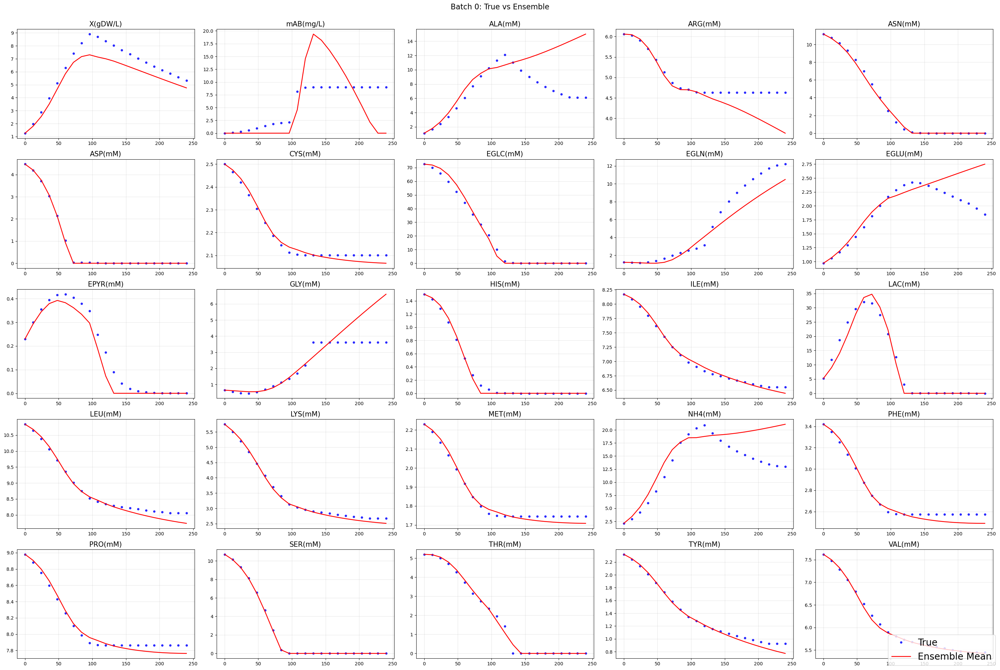

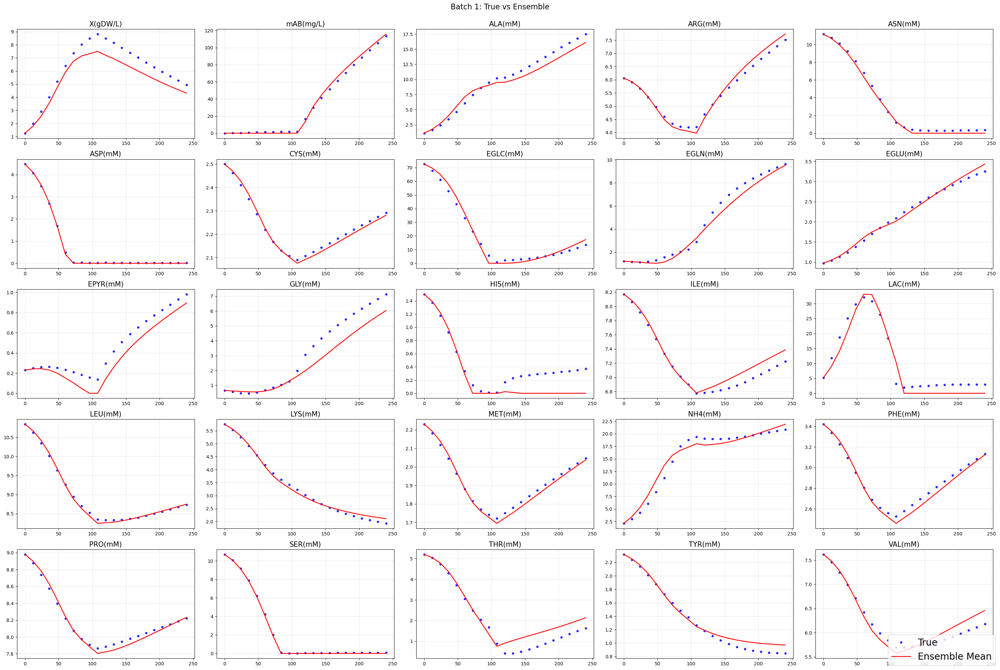

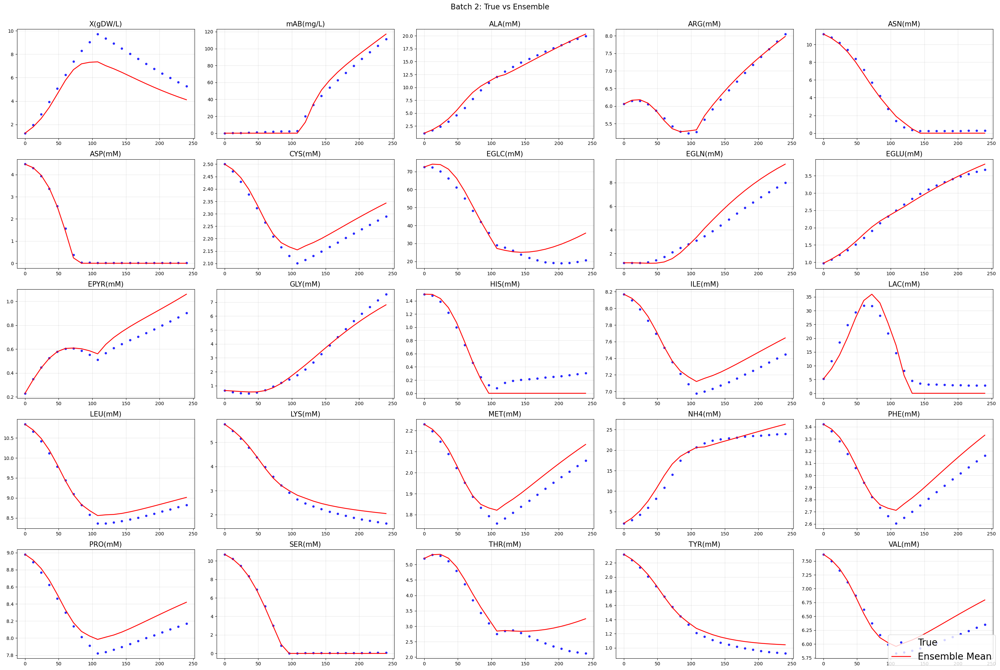

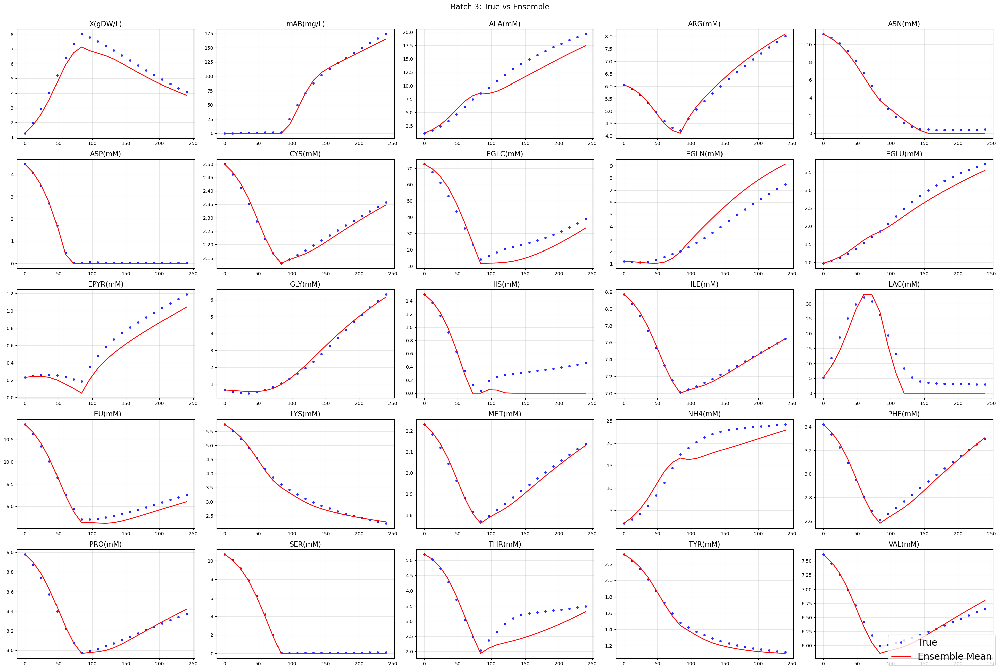

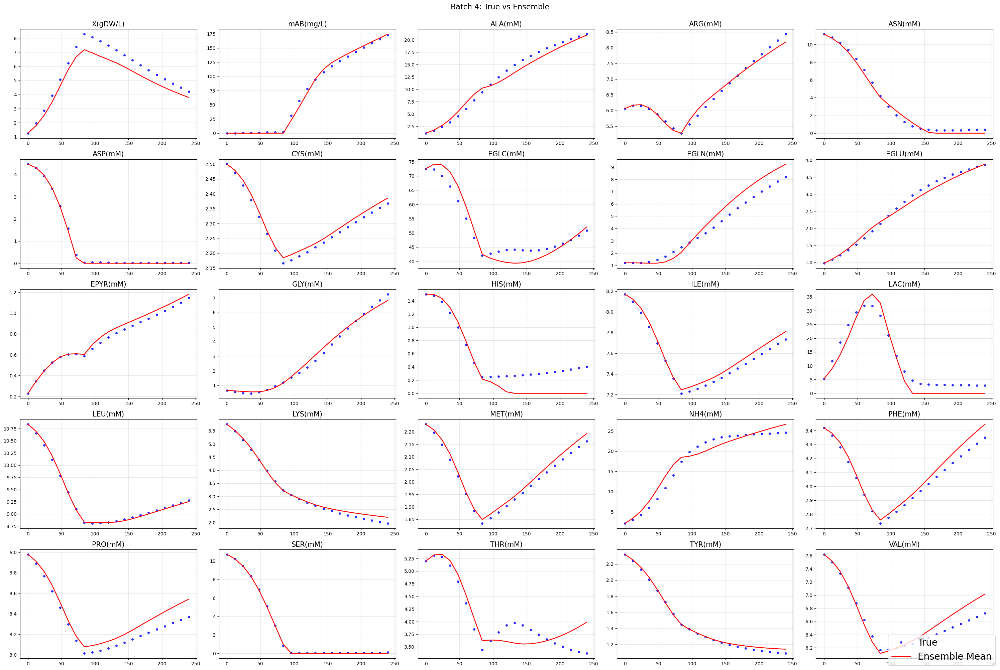

...

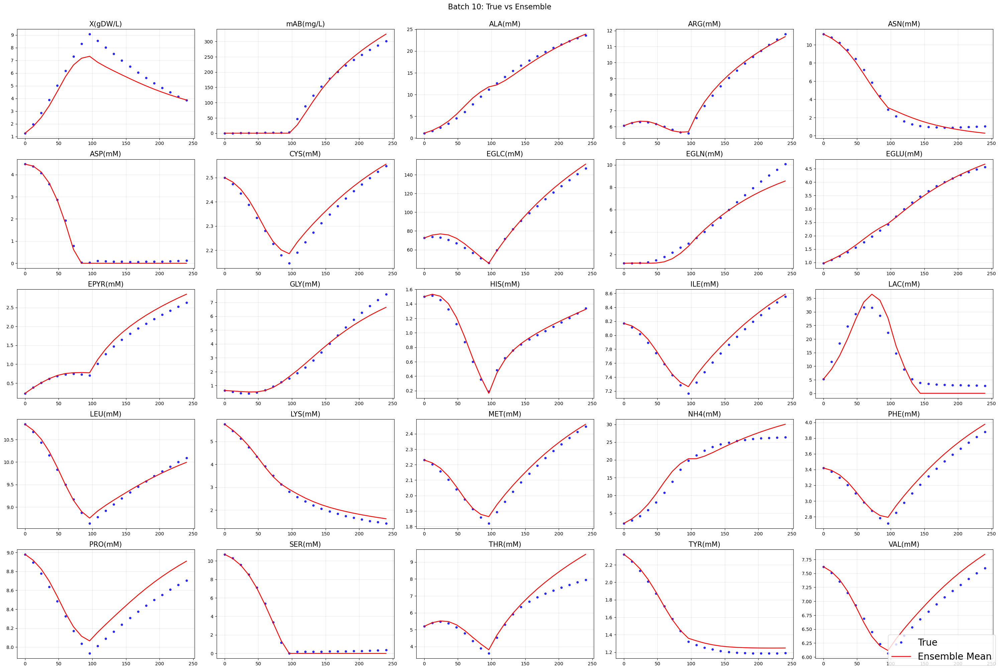

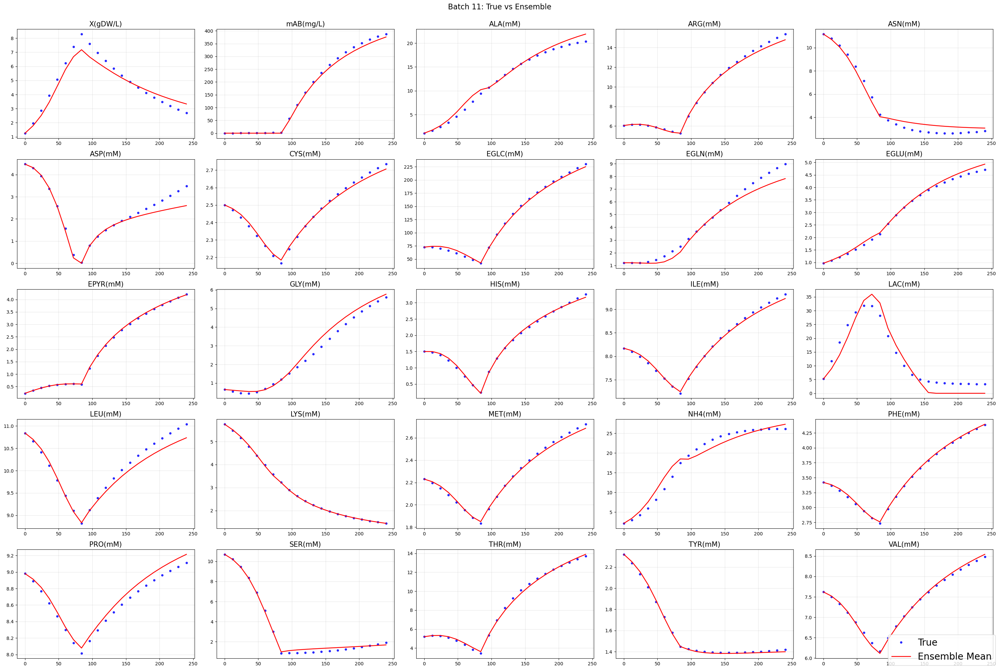

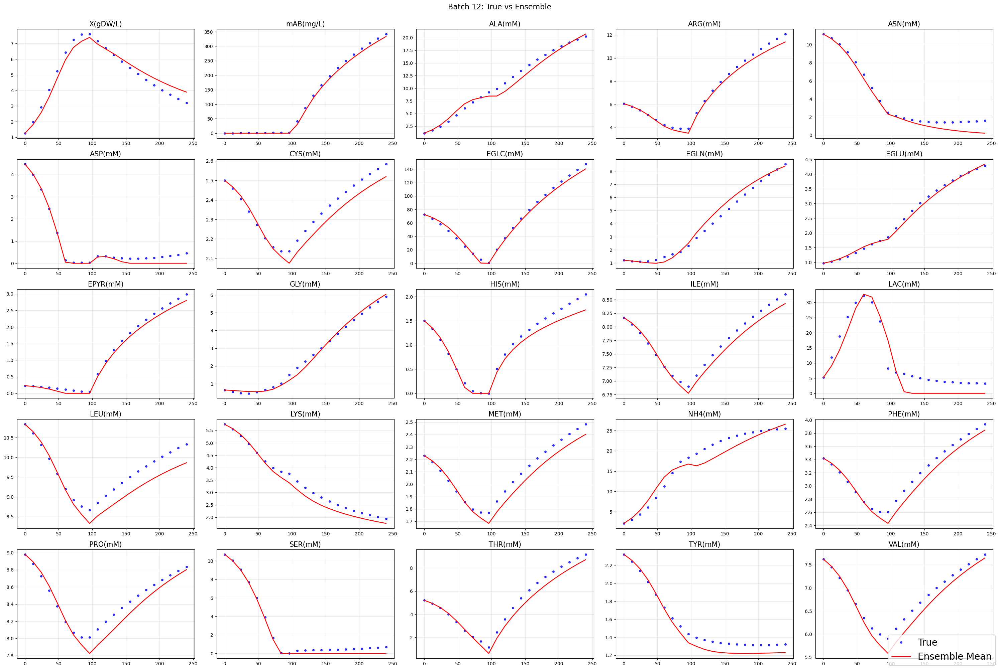

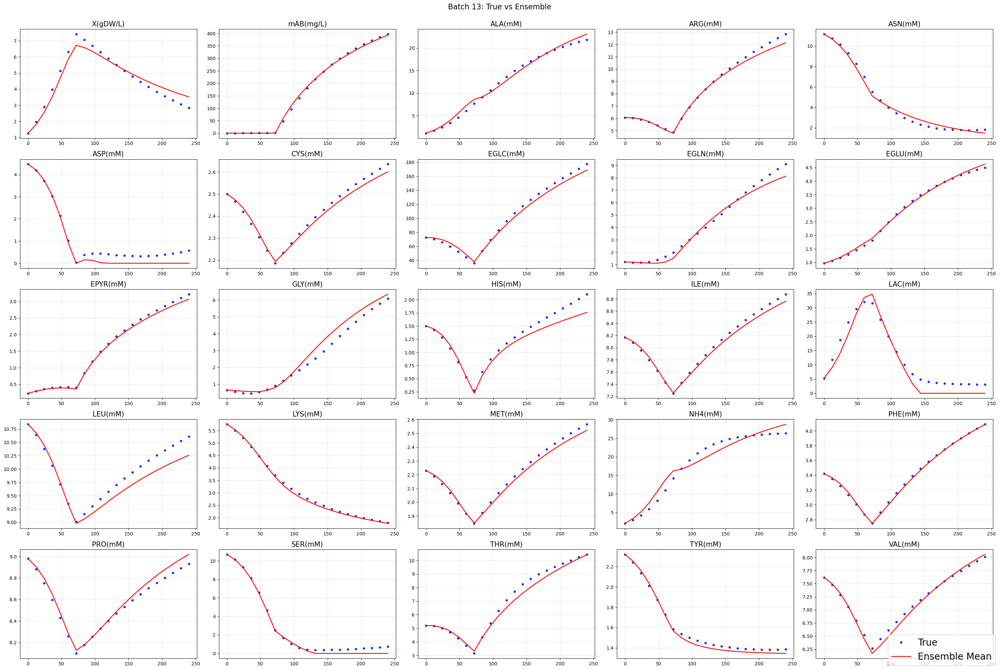

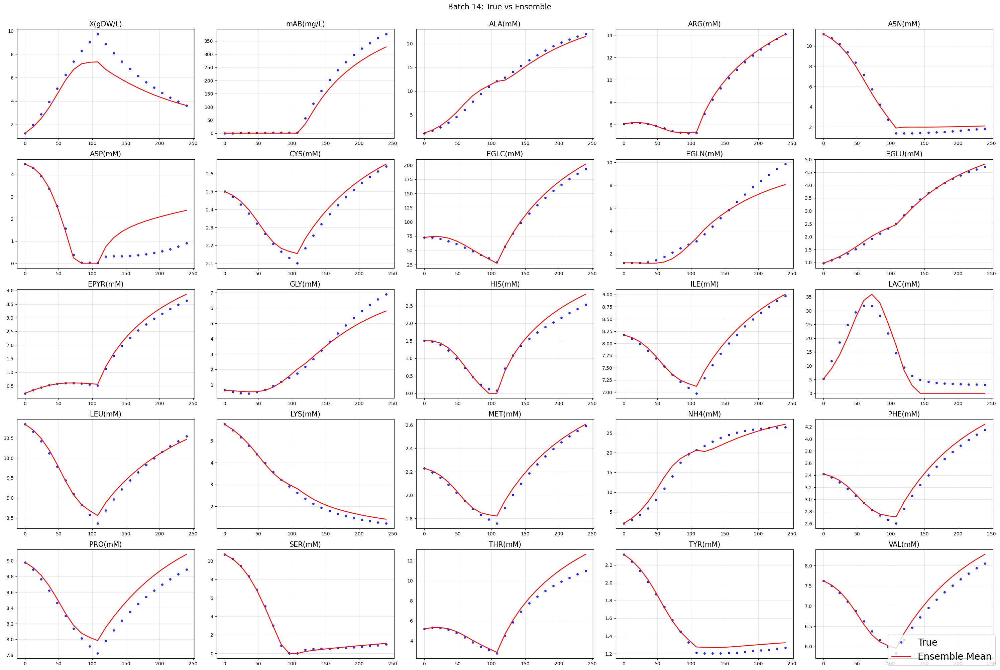

In [27]:
########################## Cell 24: Ensemble Predictions + CI + Plot #############################

all_batches = batch_numbers
n_models = len(model_paths)
pred_models_list = []

for model_path in model_paths:

    checkpoint = torch.load(model_path)
    net = FFNN(
        input_dim=inputs_num,
        hidden_layers=nh,
        output_dim=outputs_num,
        activation=activation
    )
    net.load_state_dict(checkpoint["model_state_dict"])
    net.eval()

    with torch.no_grad():

        state_with_v = torch.cat((target_data[all_batches, 0, :], volume_data[all_batches, 0].unsqueeze(1)), dim=1)
        preds = []

        for i in range(len(time_data) - 1):
            state_with_v = solve_ode_semi_parametric(
                ode_func=solve_ode,
                state=state_with_v,
                model=net,
                target_max=target_max,
                output_max=output_max,
                controls=controls_sequence[all_batches, i, :],
                t=time_data[i],
                tf=time_data[i+1],
                h=h
            )

            preds.append(state_with_v[:, :-1].detach().cpu())

        preds = torch.stack(preds)  # (T-1, B, S)
        pred_models_list.append(preds)

pred_models = torch.stack(pred_models_list)  # (n_models, T-1, B, S)

init = (target_data[all_batches, 0, :]).unsqueeze(0).unsqueeze(0)
init = init.repeat(n_models, 1, 1, 1) 

pred_models = torch.cat([init, pred_models], dim=1)  

mean_pred = pred_models.mean(dim=0)   # (T-1, B, S)
std_pred  = pred_models.std(dim=0)

if n_models > 1:
    t_value = 2.776 #LGnote: Valido apenas para k=5
else:
    t_value = 0.0

std_error = std_pred / np.sqrt(n_models)

ci_minus = mean_pred - t_value * std_error
ci_plus  = mean_pred + t_value * std_error

title_suffix = f"Ensemble (n={n_models})"

for batch_idx, b in enumerate(all_batches):

    # TRUE 
    true_traj = true_data[b]
    num_species = true_traj.shape[1]

    n_cols = 5
    n_rows = int(np.ceil(num_species / n_cols))

    fig, axs = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
    axs = axs.flatten()

    for s in range(num_species):
        ax = axs[s]
        species_label = inputs_labels[s]

        ax.plot(time_data, true_traj[:, s], "o", markersize=4, alpha=0.8, color = "blue", label="True" if s == 0 else None)
        ax.plot(time_data, mean_pred[:, batch_idx, s], color = "red", linewidth=1.8, label="Ensemble Mean" if s == 0 else None)

        if n_models > 1:
            ax.fill_between(time_data[:], ci_minus[:, batch_idx, s], ci_plus[:, batch_idx, s], color = "red",
                     alpha=0.25, label="CI" if s == 0 else None)

        ax.set_title(species_label, fontsize=15)
        ax.grid(alpha=0.3)

    for k in range(num_species, 25):
        fig.delaxes(axs[k])

    fig.suptitle(f"Batch {b}: True vs Ensemble", fontsize=16, y = 1.0)
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower right", fontsize=20)
    plt.tight_layout()
    plt.show()

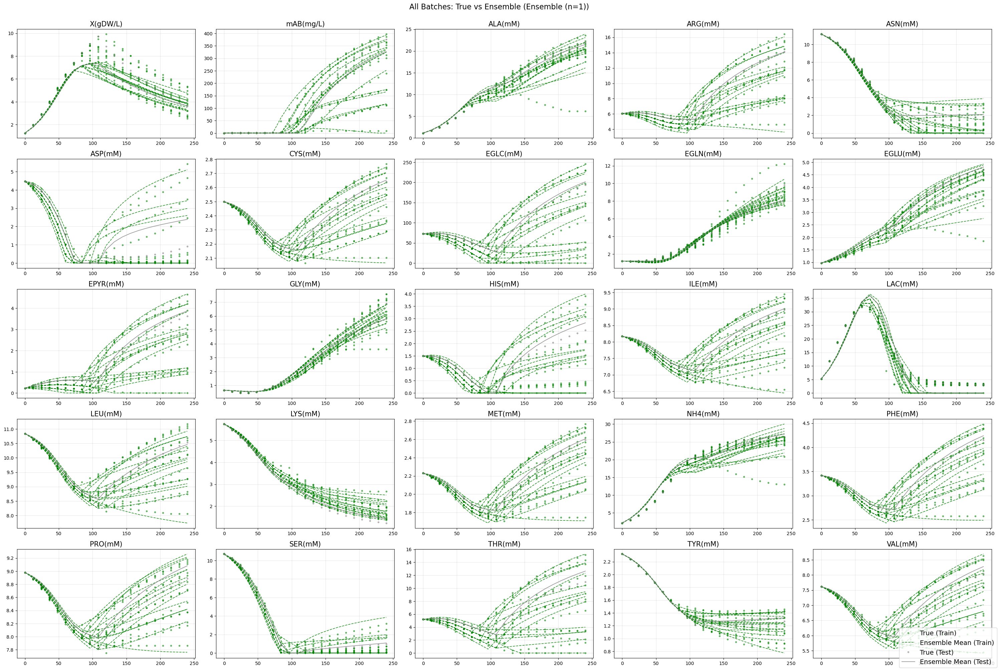

In [28]:
########################## Cell 25 (revised): Single Figure, All Batches, Train/Test Highlighted #############################

num_species = true_data.shape[2]

n_cols = 5
n_rows = int(np.ceil(num_species / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axs = axs.flatten()

#track which legend labels are already placed, so each appears once
labels_used = set()

for s in range(num_species):
    ax = axs[s]
    species_label = inputs_labels[s]

    for batch_idx, b in enumerate(all_batches):
        is_test = b in testbatch

        true_color = "grey" if is_test else "green"
        pred_color = "grey" if is_test else "green"
        true_label_key = "True (Test)" if is_test else "True (Train)"
        pred_label_key = "Ensemble Mean (Test)" if is_test else "Ensemble Mean (Train)"

        true_label = true_label_key if true_label_key not in labels_used else None
        pred_label = pred_label_key if pred_label_key not in labels_used else None
        labels_used.add(true_label_key)
        labels_used.add(pred_label_key)

        ax.plot(time_data, true_data[b, :, s], "o", markersize=3, alpha=0.5,
                color=true_color, label=true_label)
        ax.plot(time_data, mean_pred[:, batch_idx, s], "--" if not is_test else "-", color=pred_color,
                linewidth=1.3, alpha=0.8, label=pred_label)

        if n_models > 1:
            ci_label_key = "CI (Test)" if is_test else "CI (Train)"
            ci_label = ci_label_key if ci_label_key not in labels_used else None
            labels_used.add(ci_label_key)
            ax.fill_between(time_data[:], ci_minus[:, batch_idx, s], ci_plus[:, batch_idx, s],
                             color=pred_color, alpha=0.10, label=ci_label)

    ax.set_title(species_label, fontsize=15)
    ax.grid(alpha=0.3)

for k in range(num_species, n_rows*n_cols):
    fig.delaxes(axs[k])

fig.suptitle(f"All Batches: True vs Ensemble ({title_suffix})", fontsize=16, y=1.0)
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower right", fontsize=14)
plt.tight_layout()
plt.show()

mAb-specific metrics
Dataset    | Comparison      |   WMSE   |    R²   
--------------------------------------------------
Train+Val  | Noisy vs True   |  7.1164  |  0.9858 
Test       | Noisy vs True   | 11.3000  |  0.9846 

Train+Val  | Pred vs Noisy   |  7.4720  |  0.9849 
Test       | Pred vs Noisy   | 45.1195  |  0.9448 

Train+Val  | Pred vs True    |  1.5914  |  0.9968 
Test       | Pred vs True    | 21.9054  |  0.9701 


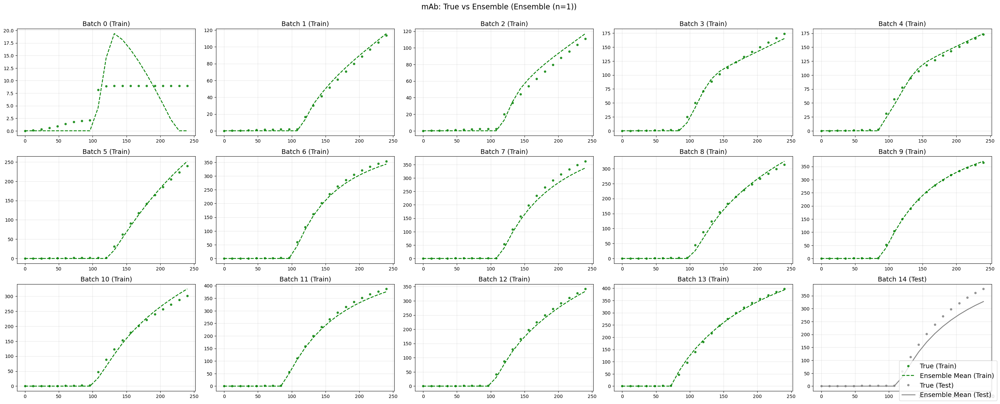

In [29]:
################################################ Cell 26: mAb-Specific Metrics and Plot ################################

################################ Isolate mAb species index ########################

mab_idx = inputs_labels.index("mAB(mg/L)")

################################ mAb-only metric wrapper ###########################

def calculate_metrics_vs_true_mab(true_data, compare_data, stds_for_data, batches):
    #slice only the mAb column, keep dims so WMSE still works on a (batches, T, 1) shape
    return calculate_metrics_vs_true(
        true_data=true_data[..., mab_idx:mab_idx+1],
        compare_data=compare_data[..., mab_idx:mab_idx+1],
        stds_for_data=stds_for_data[..., mab_idx:mab_idx+1],
        batches=batches
    )

################################ Noisy vs True (mAb) ################################

mab_noisy_vs_true_trainval_wmse, mab_noisy_vs_true_trainval_r2 = calculate_metrics_vs_true_mab(
    true_data=true_data,
    compare_data=target_data,
    stds_for_data=stds_for_data,
    batches=trainval_batches)

if testbatch != []:
    mab_noisy_vs_true_test_wmse, mab_noisy_vs_true_test_r2 = calculate_metrics_vs_true_mab(
        true_data=true_data,
        compare_data=target_data,
        stds_for_data=stds_for_data,
        batches=testbatch)

################################ Pred vs Noisy (mAb) ################################

mab_pred_vs_noisy_trainval_wmse, mab_pred_vs_noisy_trainval_r2 = calculate_metrics_vs_true_mab(
    true_data=target_data,
    compare_data=pred_full_trainval,
    stds_for_data=stds_for_data,
    batches=trainval_batches
)

if testbatch != []:
    mab_pred_vs_noisy_test_wmse, mab_pred_vs_noisy_test_r2 = calculate_metrics_vs_true_mab(
        true_data=target_data,
        compare_data=pred_full_test,
        stds_for_data=stds_for_data,
        batches=testbatch
    )

################################ Pred vs True (mAb) ################################

mab_pred_vs_true_trainval_wmse, mab_pred_vs_true_trainval_r2 = calculate_metrics_vs_true_mab(
    true_data=true_data,
    compare_data=pred_full_trainval,
    stds_for_data=stds_for_data,
    batches=trainval_batches
)

if testbatch != []:
    mab_pred_vs_true_test_wmse, mab_pred_vs_true_test_r2 = calculate_metrics_vs_true_mab(
        true_data=true_data,
        compare_data=pred_full_test,
        stds_for_data=stds_for_data,
        batches=testbatch
    )

################################ Assemble mAb metrics table ##########################

mab_records = []

mab_records.append({"Dataset": "Train+Val", "Comparison": "Noisy vs True", "WMSE": mab_noisy_vs_true_trainval_wmse, "R2": mab_noisy_vs_true_trainval_r2})
mab_records.append({"Dataset": "Test", "Comparison": "Noisy vs True", "WMSE": mab_noisy_vs_true_test_wmse, "R2": mab_noisy_vs_true_test_r2})

mab_records.append({"Dataset": "\nTrain+Val ", "Comparison": "Pred vs Noisy", "WMSE": mab_pred_vs_noisy_trainval_wmse, "R2": mab_pred_vs_noisy_trainval_r2})
mab_records.append({"Dataset": "Test", "Comparison": "Pred vs Noisy", "WMSE": mab_pred_vs_noisy_test_wmse, "R2": mab_pred_vs_noisy_test_r2})

mab_records.append({"Dataset": "\nTrain+Val ", "Comparison": "Pred vs True", "WMSE": mab_pred_vs_true_trainval_wmse, "R2": mab_pred_vs_true_trainval_r2})
mab_records.append({"Dataset": "Test", "Comparison": "Pred vs True", "WMSE": mab_pred_vs_true_test_wmse, "R2": mab_pred_vs_true_test_r2})

mab_header = (f"{'Dataset':<10} | {'Comparison':<15} | {'WMSE':^8} | {'R²':^8}")

print("mAb-specific metrics")
print(mab_header)
print("-" * len(mab_header))

for r in mab_records:
    print(f"{r['Dataset']:<10} | {r['Comparison']:<15} | {r['WMSE']:^8.4f} | {r['R2']:^8.4f}")

########################## mAb Plot: All Batches, one subplot each, Train/Test Highlighted #############################

n_cols = 5
n_rows = int(np.ceil(len(all_batches) / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(6*n_cols, 4*n_rows))
axs = axs.flatten()

labels_used = set()

for batch_idx, b in enumerate(all_batches):
    ax = axs[batch_idx]
    is_test = b in testbatch

    true_color = "grey" if is_test else "green"
    pred_color = "grey" if is_test else "green"
    group_label = "Test" if is_test else "Train"

    true_label_key = f"True ({group_label})"
    pred_label_key = f"Ensemble Mean ({group_label})"

    true_label = true_label_key if true_label_key not in labels_used else None
    pred_label = pred_label_key if pred_label_key not in labels_used else None
    labels_used.add(true_label_key)
    labels_used.add(pred_label_key)

    ax.plot(time_data, true_data[b, :, mab_idx], "o", markersize=4, alpha=0.8,
            color=true_color, label=true_label)
    ax.plot(time_data, mean_pred[:, batch_idx, mab_idx], "-" if is_test else "--",
            color=pred_color, linewidth=1.8, label=pred_label)

    if n_models > 1:
        ci_label_key = f"CI ({group_label})"
        ci_label = ci_label_key if ci_label_key not in labels_used else None
        labels_used.add(ci_label_key)
        ax.fill_between(time_data[:], ci_minus[:, batch_idx, mab_idx], ci_plus[:, batch_idx, mab_idx],
                         color=pred_color, alpha=0.25, label=ci_label)

    ax.set_title(f"Batch {b} ({group_label})", fontsize=14)
    ax.grid(alpha=0.3)

for k in range(len(all_batches), n_rows*n_cols):
    fig.delaxes(axs[k])

fig.suptitle(f"mAb: True vs Ensemble ({title_suffix})", fontsize=16, y=1.0)
handles, labels = [], []
for ax in axs[:len(all_batches)]:
    h, l = ax.get_legend_handles_labels()
    for hi, li in zip(h, l):
        if li not in labels:
            handles.append(hi)
            labels.append(li)

fig.legend(handles, labels, loc="lower right", fontsize=14)
plt.tight_layout()
plt.show()